# County unemployment early warning: EDA, regularized logistic regression, PCA, and UMAP

**Question.** For a county in month *t*, will its unemployment rate rise by **at least 0.5 percentage points over the next 3 months**?
That is `y_label = (rate(t+3) - rate(t) >= 0.5)` in `marts.county_month`.

**What this notebook does**
1. **Load** the mart from MotherDuck (read-only `SELECT`; nothing is written anywhere).
2. **EDA**: class balance, seasonality, the COVID shock, feature distributions, correlations, and single-feature signal.
3. **Build a validation design that respects time**: an out-of-time test year plus *stratified, grouped* k-fold CV.
4. **Logistic regression with every regularization type** (L2, L1, elastic net, and none as a reference), tuned with `GridSearchCV`.
5. **Evaluate** with proper metrics: binary cross-entropy / log loss, ROC and ROC AUC, PR AUC, confusion matrix, accuracy, precision, recall, F1, and calibration.
6. **PCA**: does compressing the features into principal components help or hurt?
7. **UMAP**: a nonlinear view of the same data, for comparison.

> Why logistic regression first? It is the standard baseline for a binary target: fast, interpretable (one coefficient per feature),
> and it produces probabilities that are often well calibrated. Anything more complex (e.g. gradient boosting) has to beat it.

**Notebook 02** (`02_svm.ipynb`) reuses this notebook's exact data design (same split, tuning sample, and folds) to test support
vector machines against the logistic regression built here. **Notebook 03** (`03_final_model.ipynb`) compares the finalists
and declares the best model.

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_predict, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, precision_recall_curve)
from sklearn.calibration import CalibrationDisplay
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)
RNG = 42

## 1. Load the data

The mart has one row per **county × month**. Columns starting with `f_` are features; everything else is an ID, a target, or context.
If `MOTHERDUCK_TOKEN` isn't set, the cell falls back to the parquet export in `data/`.

In [2]:
if os.environ.get("MOTHERDUCK_TOKEN"):
    con = duckdb.connect("md:unemployment")
    df = con.sql("select * from marts.county_month order by county_fips, month").df()
    con.close()
    source = "MotherDuck: unemployment.marts.county_month"
else:
    df = pd.read_parquet("data/county_month.parquet").sort_values(["county_fips", "month"])
    source = "data/county_month.parquet"

df["month"] = pd.to_datetime(df["month"])
FEATURES = [c for c in df.columns if c.startswith("f_")]
print(f"source: {source}")
print(f"rows: {len(df):,}   counties: {df.county_fips.nunique():,}   months: {df.month.min():%Y-%m} to {df.month.max():%Y-%m}")
print(f"{len(FEATURES)} features: {FEATURES}")
df.head()

source: MotherDuck: unemployment.marts.county_month
rows: 439,960   counties: 3,144   months: 2015-01 to 2026-08
26 features: ['f_rate', 'f_rate_chg_1m', 'f_rate_chg_3m', 'f_rate_chg_6m', 'f_rate_chg_12m', 'f_rate_mean_12m', 'f_rate_std_12m', 'f_rate_minus_min_36m', 'f_lf_pct_3m', 'f_lf_pct_12m', 'f_emp_pct_3m', 'f_emp_pct_12m', 'f_unemp_pct_3m', 'f_month_sin', 'f_month_cos', 'f_nat_med_chg_3m', 'f_state_med_chg_3m', 'f_fred_unrate', 'f_fred_unrate_chg_3m', 'f_fred_fedfunds', 'f_fred_fedfunds_chg_6m', 'f_fred_cpi_yoy_pct', 'f_fred_t10y2y_mean', 'f_fred_indpro_yoy_pct', 'f_fred_payems_pct_chg_3m', 'f_fred_icsa_pct_chg_3m']


,county_month_id,county_fips,state_fips,state_abbr,county_name,month,decision_date,f_rate,f_rate_chg_1m,f_rate_chg_3m,f_rate_chg_6m,f_rate_chg_12m,f_rate_mean_12m,f_rate_std_12m,f_rate_minus_min_36m,f_lf_pct_3m,f_lf_pct_12m,f_emp_pct_3m,f_emp_pct_12m,f_unemp_pct_3m,f_month_sin,f_month_cos,f_nat_med_chg_3m,f_state_med_chg_3m,fred_latest_ref_month,f_fred_unrate,f_fred_unrate_chg_3m,f_fred_fedfunds,f_fred_fedfunds_chg_6m,f_fred_cpi_yoy_pct,f_fred_t10y2y_mean,f_fred_indpro_yoy_pct,f_fred_payems_pct_chg_3m,f_fred_icsa_pct_chg_3m,y_delta_3m,y_label,is_labeled,labor_force
0,01001-2015-01,01001,01,AL,Autauga County,2015-01-01,2015-03-01,5.7000,0.8000,0.3000,-0.6000,-0.7000,5.7500,0.4908,0.8000,-0.6854,-0.6196,-0.9388,0.2041,3.7356,0.5000,0.8660,0.8000,0.6000,2015-02-01,5.5000,-0.3000,0.1100,0.0200,-0.2299,1.3563,2.7262,0.5268,3.3093,-1.0000,False,True,25503.0000
1,01001-2015-02,01001,01,AL,Autauga County,2015-02-01,2015-04-01,5.4000,-0.3000,0.2000,-0.7000,-1.1000,5.6583,0.4379,0.5000,0.4304,-0.5270,0.2229,0.6009,4.1822,0.8660,0.5000,0.5000,0.4000,2015-03-01,5.4000,-0.2000,0.1100,0.0200,-0.0870,1.4023,1.3047,0.3983,-0.1757,-0.3000,False,True,25670.0000
2,01001-2015-03,01001,01,AL,Autauga County,2015-03-01,2015-05-01,5.1000,-0.3000,0.2000,-0.5000,-1.2000,5.5583,0.4144,0.2000,1.3498,-0.5923,1.1619,0.7397,5.0000,1.0000,0.0000,0.3000,0.1000,2015-04-01,5.4000,-0.3000,0.1200,0.0300,-0.0220,1.3950,-0.0027,0.4468,-0.5563,0.4000,False,True,25680.0000
3,01001-2015-04,01001,01,AL,Autauga County,2015-04-01,2015-06-01,4.7000,-0.4000,-1.0000,-0.7000,-0.8000,5.4917,0.4833,0.0000,1.0901,0.2333,2.1447,1.0942,-16.4820,0.8660,-0.5000,-1.1000,-1.2000,2015-05-01,5.6000,0.1000,0.1200,0.0300,-0.1040,1.5885,-0.6445,0.5049,-9.0456,1.0000,True,True,25781.0000
4,01001-2015-05,01001,01,AL,Autauga County,2015-05-01,2015-07-01,5.1000,0.4000,-0.3000,-0.1000,-0.4000,5.4583,0.4963,0.4000,1.1998,0.7993,1.5819,1.2440,-5.4480,0.5000,-0.8660,-0.6000,-0.6000,2015-06-01,5.3000,-0.1000,0.1300,0.0100,0.0350,1.6750,-1.4605,0.5578,-3.6092,0.3000,False,True,25978.0000


### 1.1 Missing values

Lag and window features are null when there isn't enough history yet (for example a 12-month change in the first 12 months).
The rates below are tiny, so **median imputation inside the model pipeline** is enough. Putting it *inside* the pipeline means the
median is learned from the training fold only, so nothing leaks from validation or test data.

In [3]:
nulls = df[FEATURES + ["y_delta_3m"]].isna().mean().sort_values(ascending=False).rename("null_rate")
nulls.to_frame().T

,y_delta_3m,f_rate_chg_6m,f_lf_pct_3m,f_emp_pct_3m,f_rate_chg_3m,f_unemp_pct_3m,f_rate_chg_1m,f_fred_unrate_chg_3m,f_state_med_chg_3m,f_nat_med_chg_3m,f_lf_pct_12m,f_rate_chg_12m,f_emp_pct_12m,f_rate_minus_min_36m,f_rate,f_fred_cpi_yoy_pct,f_fred_unrate,f_rate_std_12m,f_rate_mean_12m,f_month_sin,f_month_cos,f_fred_fedfunds_chg_6m,f_fred_fedfunds,f_fred_t10y2y_mean,f_fred_indpro_yoy_pct,f_fred_payems_pct_chg_3m,f_fred_icsa_pct_chg_3m
null_rate,0.0357,0.0143,0.0143,0.0143,0.0143,0.0143,0.0143,0.0143,0.0143,0.0143,0.0072,0.0072,0.0072,0.0071,0.0071,0.0071,0.0071,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


## 2. Exploratory data analysis

From here on, EDA uses only **labeled** rows (`is_labeled`, i.e. month *t+3* already exists). The newest 3 months have no target
yet; those are the rows a model would score in real time.

labeled rows: 424,242  (2015-01 to 2026-05)
positive rate (y=1): 0.270


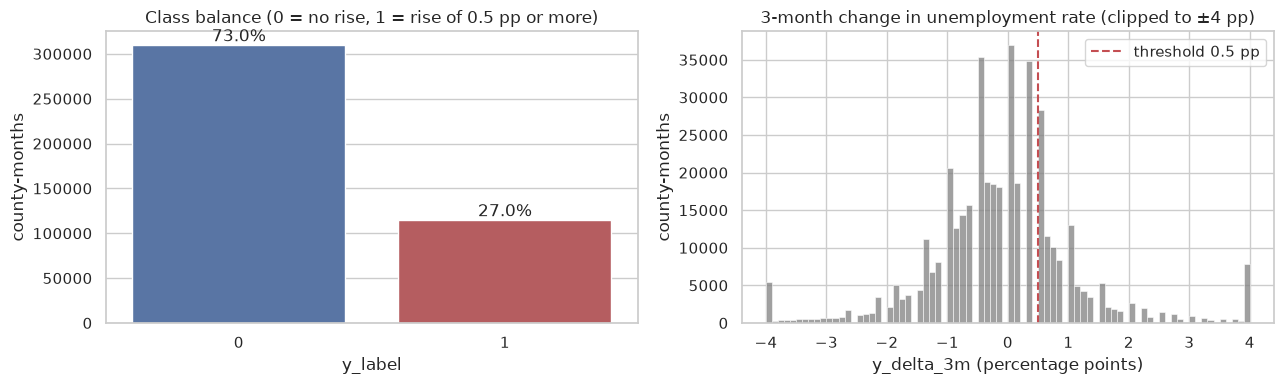

In [4]:
lab = df[df["is_labeled"]].copy()
lab["y"] = lab["y_label"].astype(int)
print(f"labeled rows: {len(lab):,}  ({lab.month.min():%Y-%m} to {lab.month.max():%Y-%m})")
print(f"positive rate (y=1): {lab.y.mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x=lab["y"], ax=axes[0], hue=lab["y"], palette=["#4C72B0", "#C44E52"], legend=False)
axes[0].set_title("Class balance (0 = no rise, 1 = rise of 0.5 pp or more)")
axes[0].set_xlabel("y_label"); axes[0].set_ylabel("county-months")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height()/len(lab):.1%}", (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
sns.histplot(lab["y_delta_3m"].clip(-4, 4), bins=80, ax=axes[1], color="gray")
axes[1].axvline(0.5, color="#C44E52", ls="--", label="threshold 0.5 pp")
axes[1].set_title("3-month change in unemployment rate (clipped to ±4 pp)")
axes[1].set_xlabel("y_delta_3m (percentage points)"); axes[1].set_ylabel("county-months"); axes[1].legend()
plt.tight_layout(); plt.show()

**Why this matters.** The classes are **imbalanced but not extremely** (about 1 positive for every 3 negatives). Two consequences:
- **Accuracy alone is misleading.** Predicting "no rise" for everyone already scores about 73%. That's why we also report precision,
  recall, F1, ROC AUC, PR AUC, and log loss.
- **Stratification is useful.** Every CV fold should keep roughly the same positive rate, so fold-to-fold scores differ because of
  the model, not because one fold happened to get more positives.

The change distribution is centered near zero with a heavy right tail (the COVID spike). The threshold sits in the right shoulder.

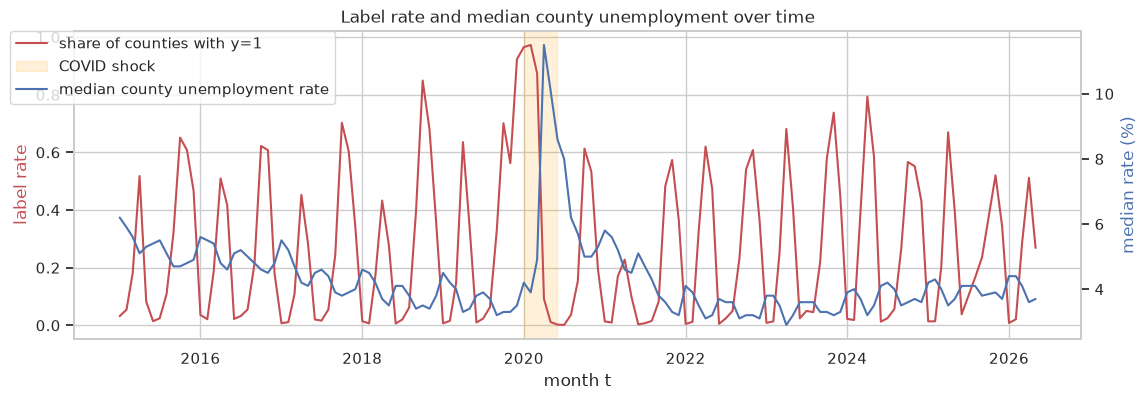

In [5]:
by_month = lab.groupby("month").agg(label_rate=("y", "mean"), median_rate=("f_rate", "median"))
fig, ax1 = plt.subplots(figsize=(13, 4))
ax1.plot(by_month.index, by_month.label_rate, color="#C44E52", label="share of counties with y=1")
ax1.set_ylabel("label rate", color="#C44E52")
ax2 = ax1.twinx()
ax2.plot(by_month.index, by_month.median_rate, color="#4C72B0", label="median county unemployment rate")
ax2.set_ylabel("median rate (%)", color="#4C72B0"); ax2.grid(False)
ax1.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2020-06-01"), color="orange", alpha=0.15, label="COVID shock")
ax1.set_title("Label rate and median county unemployment over time"); ax1.set_xlabel("month t")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.9)); plt.show()

**Reading the plot.** The label rate swings in a strong **yearly sawtooth**. County rates are *not seasonally adjusted*, so
rises at the same time each year (winter in tourism, farm, and construction counties) produce positives every year.
The COVID months (early 2020) are an extreme outlier. Almost every county rose. The following months were the opposite.
A model can look good by learning *the calendar* plus *the COVID shock*. The heatmap below makes the seasonality explicit.

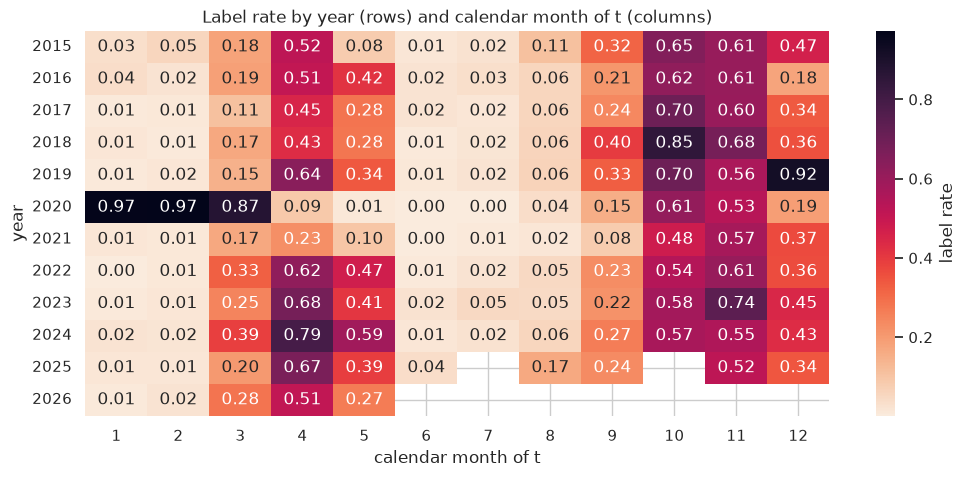

In [6]:
heat = lab.assign(year=lab.month.dt.year, cal_month=lab.month.dt.month).pivot_table(index="year", columns="cal_month", values="y", aggfunc="mean")
plt.figure(figsize=(12, 5))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="rocket_r", cbar_kws={"label": "label rate"})
plt.title("Label rate by year (rows) and calendar month of t (columns)"); plt.xlabel("calendar month of t"); plt.ylabel("year")
plt.show()

**Significance.** Some calendar months have a label rate several times higher than others, in almost every year. So the
features `f_month_sin` / `f_month_cos` will carry a lot of the signal, and a **seasonal-naive baseline** (built in §2.5) is the honest
bar to beat. 2020 stands out across the row, which is the COVID effect.

### 2.1 Feature distributions

Each panel is one feature (a 50k-row sample, clipped to its 1st–99th percentile so outliers don't flatten the plot). The colors
split by label. Where the red and blue shapes differ, that feature separates the classes on its own.

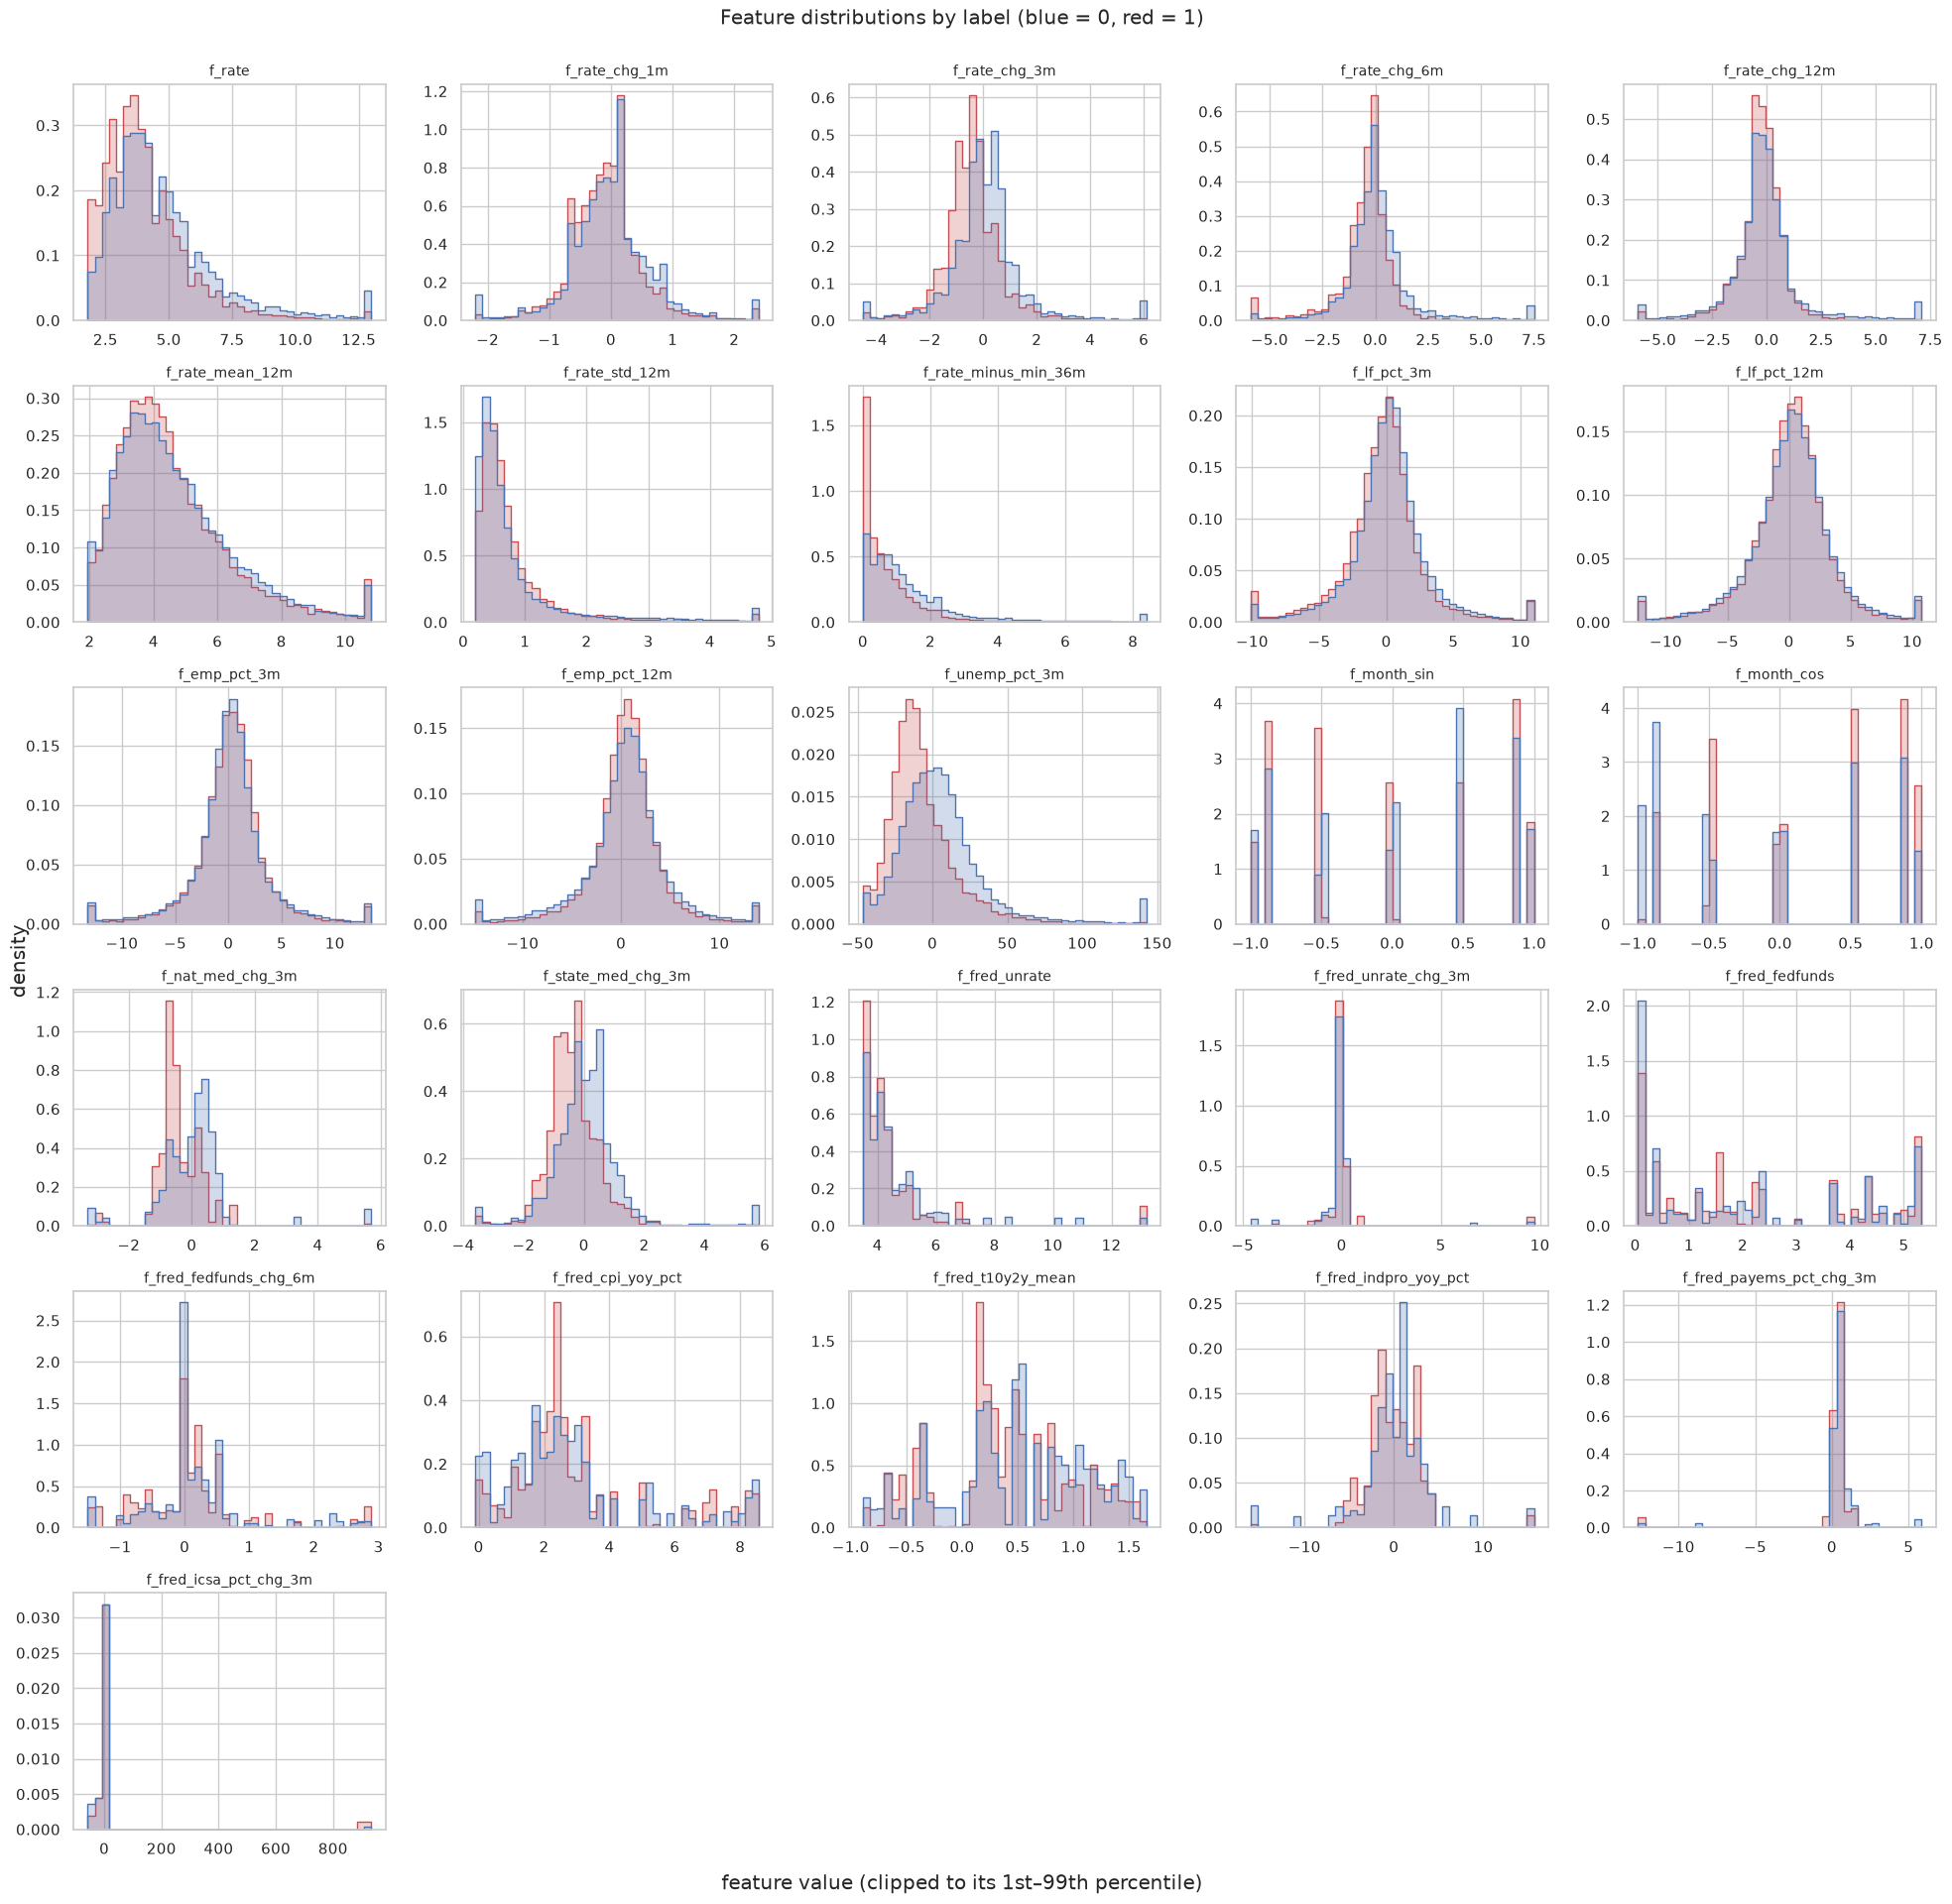

In [7]:
samp = lab.sample(50_000, random_state=RNG)
n = len(FEATURES); ncols = 5; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 3.2 * nrows))
for ax, col in zip(axes.flat, FEATURES):
    lo, hi = samp[col].quantile([0.01, 0.99])
    sns.histplot(data=samp.assign(v=samp[col].clip(lo, hi)), x="v", hue="y", bins=40, stat="density",
                 common_norm=False, element="step", ax=ax, palette=["#4C72B0", "#C44E52"], legend=False)
    ax.set_title(col, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.flat[n:]:
    ax.remove()
fig.supxlabel("feature value (clipped to its 1st–99th percentile)"); fig.supylabel("density")
fig.suptitle("Feature distributions by label (blue = 0, red = 1)", y=1.0); plt.tight_layout(); plt.show()

In [8]:
lab[FEATURES].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]

,mean,std,min,25%,50%,75%,max
f_rate,4.5939,2.1951,0.3000,3.2000,4.1000,5.4000,36.1000
f_rate_chg_1m,-0.0154,1.0418,-22.5000,-0.4000,-0.1000,0.3000,32.0000
f_rate_chg_3m,-0.0407,1.7203,-28.4000,-0.7000,-0.1000,0.5000,31.8000
f_rate_chg_6m,-0.0669,2.0429,-31.4000,-0.7000,-0.1000,0.4000,33.1000
f_rate_chg_12m,-0.1829,1.9755,-32.4000,-0.8000,-0.2000,0.3000,32.2000
f_rate_mean_12m,4.6642,1.8887,0.3545,3.3667,4.2667,5.5333,24.9500
f_rate_std_12m,0.8468,0.9166,0.0522,0.3825,0.5483,0.8721,13.8329
f_rate_minus_min_36m,1.2524,1.6602,0.0000,0.3000,0.8000,1.5000,33.1000
f_lf_pct_3m,0.1024,4.8565,-82.8372,-1.2823,0.0980,1.3889,376.9759
f_lf_pct_12m,0.0919,4.3899,-75.9698,-1.4953,0.2756,1.8821,223.8806


**Scale.** The features sit on very different scales (fed funds rate in percent, ICSA percent changes in the tens, sin/cos in [-1, 1]).
Regularized logistic regression **penalizes coefficient size**, so without standardization the penalty would hit features unevenly
just because of their units. That's why every model below has a `StandardScaler` step. PCA also requires scaling, otherwise the
largest-variance units dominate the components.

### 2.2 Correlation between features

Spearman (rank) correlation is used because several features are skewed. Strongly correlated blocks matter for two reasons:
- **For L1**, it tends to keep one feature from a correlated group and zero out the rest (somewhat arbitrarily).
- **For PCA**, correlated blocks are exactly what gets compressed into a single component.

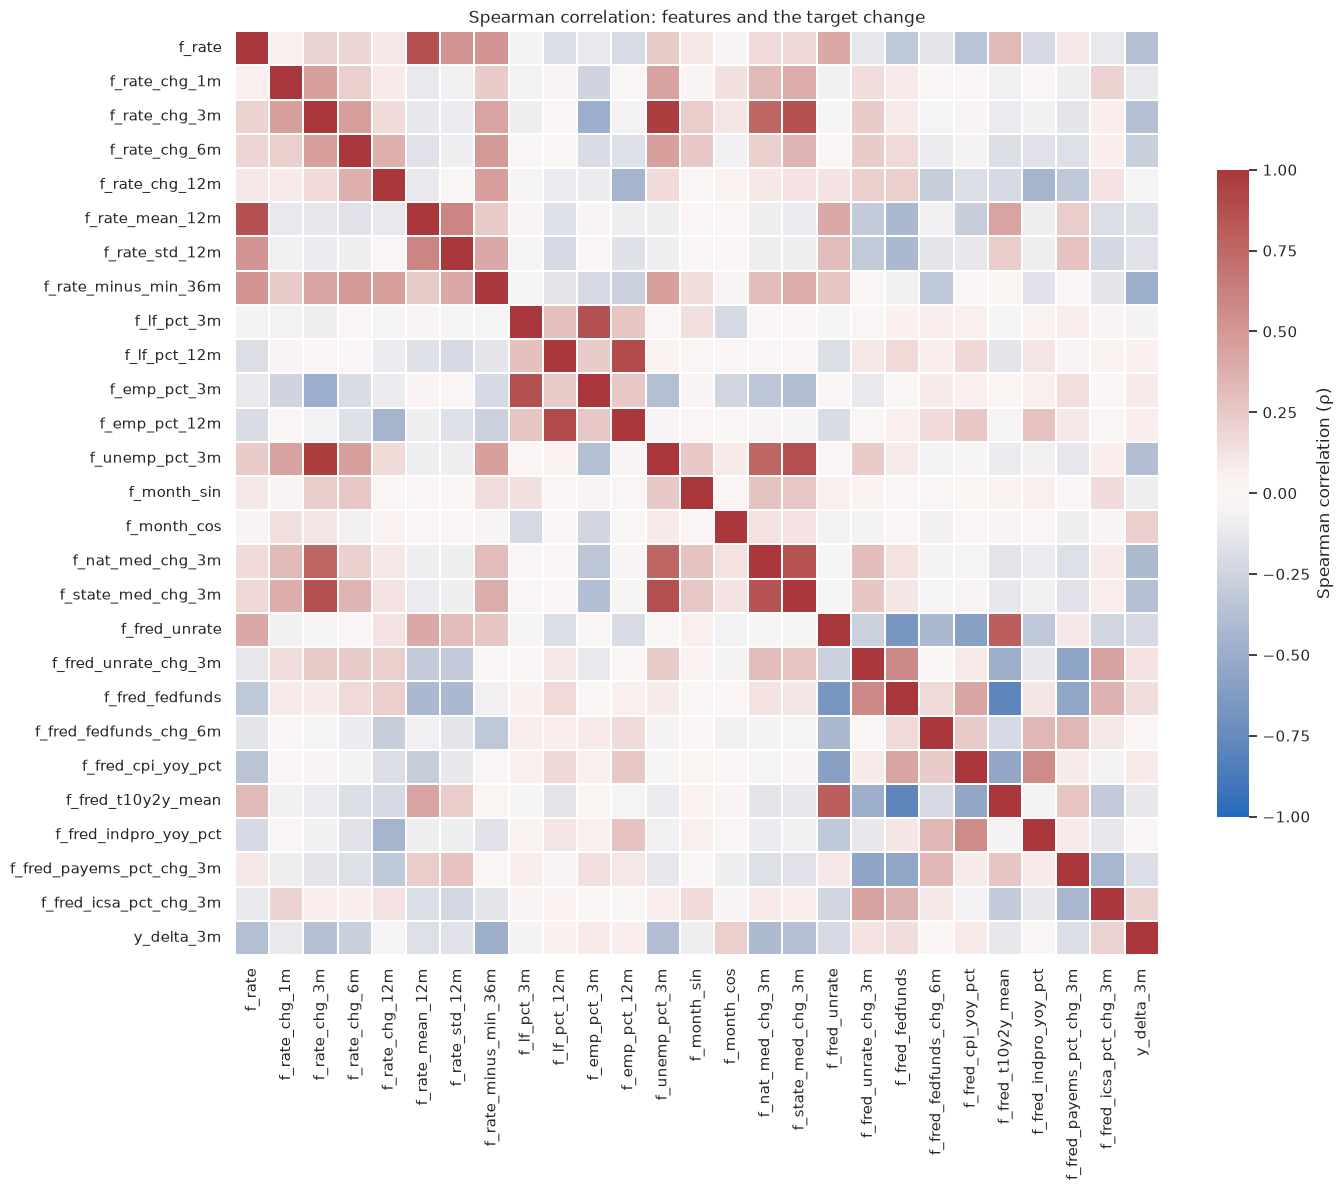

,level_0,level_1,rho,abs_rho
64,f_rate_chg_3m,f_unemp_pct_3m,0.9679,0.9679
245,f_lf_pct_12m,f_emp_pct_12m,0.8937,0.8937
328,f_unemp_pct_3m,f_state_med_chg_3m,0.8774,0.8774
5,f_rate,f_rate_mean_12m,0.8741,0.8741
68,f_rate_chg_3m,f_state_med_chg_3m,0.8732,0.8732
218,f_lf_pct_3m,f_emp_pct_3m,0.8686,0.8686
406,f_nat_med_chg_3m,f_state_med_chg_3m,0.8553,0.8553
464,f_fred_unrate,f_fred_t10y2y_mean,0.8046,0.8046
516,f_fred_fedfunds,f_fred_t10y2y_mean,-0.7762,0.7762
327,f_unemp_pct_3m,f_nat_med_chg_3m,0.7645,0.7645


In [9]:
corr = samp[FEATURES + ["y_delta_3m"]].corr(method="spearman")
plt.figure(figsize=(15, 12))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, square=True, linewidths=0.3, cbar_kws={"shrink": 0.7, "label": "Spearman correlation (ρ)"})
plt.title("Spearman correlation: features and the target change"); plt.show()

pairs = (corr.loc[FEATURES, FEATURES].where(np.triu(np.ones((n, n), bool), 1)).stack()
         .rename("rho").reset_index().assign(abs_rho=lambda d: d.rho.abs()).sort_values("abs_rho", ascending=False))
pairs.head(10)

### 2.3 Signal from each feature alone (univariate ROC AUC)

For each feature, treat its raw value as a score and compute ROC AUC against `y`. **0.5 = no signal**. Above 0.5 means higher values
go with rises; below 0.5 means higher values go with *no* rise (still useful, just inverted). This is a quick, model-free ranking of
where the signal is.

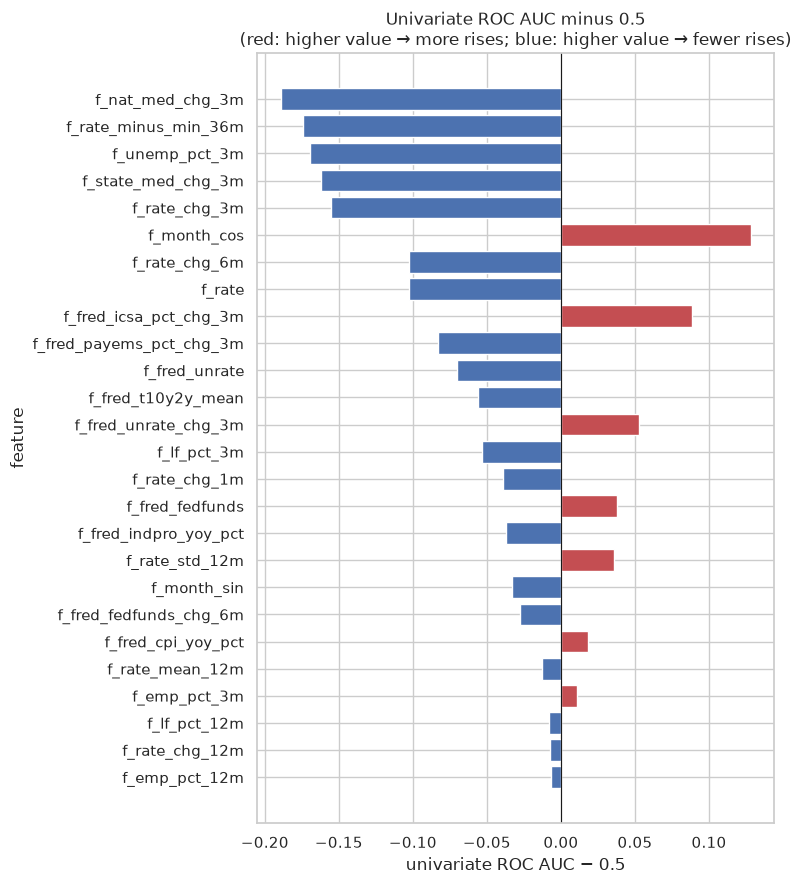

,auc,strength
f_nat_med_chg_3m,0.3109,0.1891
f_rate_minus_min_36m,0.3256,0.1744
f_unemp_pct_3m,0.3305,0.1695
f_state_med_chg_3m,0.3378,0.1622
f_rate_chg_3m,0.3448,0.1552
f_month_cos,0.6280,0.1280
f_rate_chg_6m,0.3975,0.1025
f_rate,0.3975,0.1025


In [10]:
uni = pd.Series({c: roc_auc_score(lab.y, lab[c].fillna(lab[c].median())) for c in FEATURES}, name="auc")
uni = uni.to_frame().assign(strength=lambda d: (d.auc - 0.5).abs()).sort_values("strength", ascending=True)
plt.figure(figsize=(8, 9))
plt.barh(uni.index, uni.auc - 0.5, color=np.where(uni.auc > 0.5, "#C44E52", "#4C72B0"))
plt.axvline(0, color="k", lw=0.8)
plt.title("Univariate ROC AUC minus 0.5\n(red: higher value → more rises; blue: higher value → fewer rises)")
plt.xlabel("univariate ROC AUC − 0.5"); plt.ylabel("feature"); plt.tight_layout(); plt.show()
uni.sort_values("strength", ascending=False).head(8)

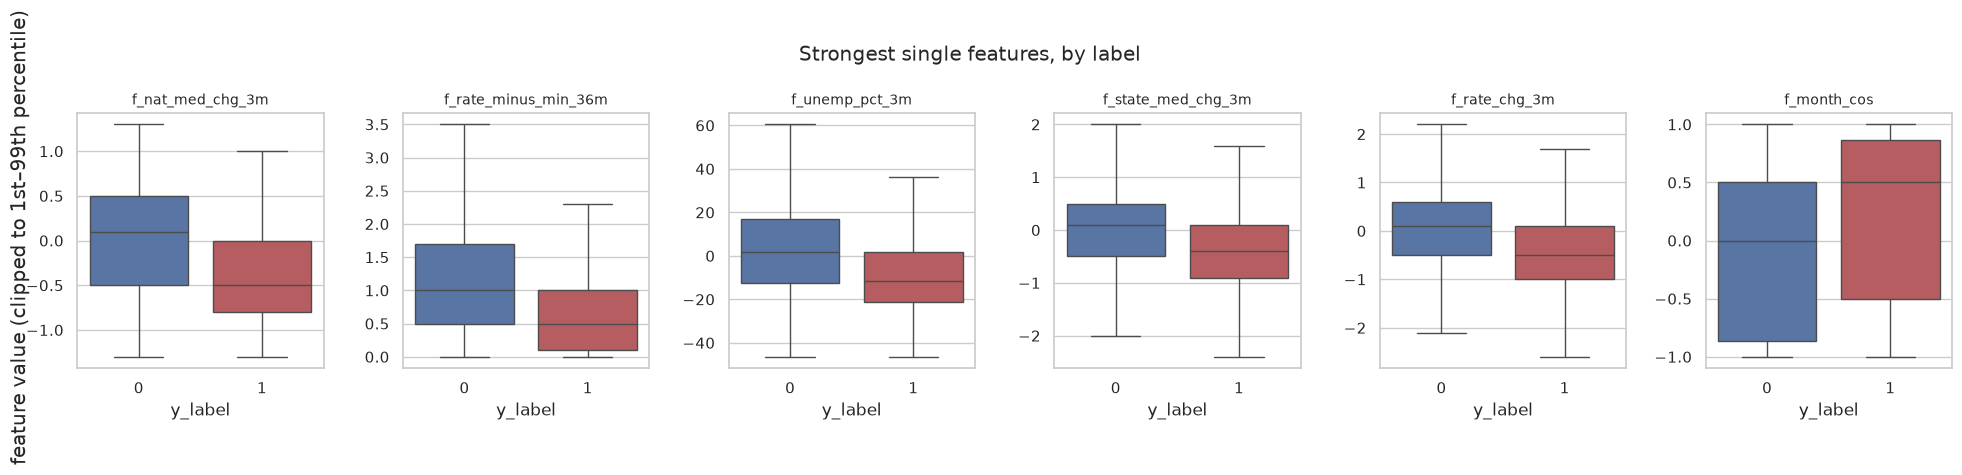

In [11]:
top6 = uni.sort_values("strength", ascending=False).index[:6]
fig, axes = plt.subplots(1, 6, figsize=(20, 4))
for ax, col in zip(axes, top6):
    lo, hi = samp[col].quantile([0.01, 0.99])
    sns.boxplot(x=samp.y, y=samp[col].clip(lo, hi), ax=ax, hue=samp.y, palette=["#4C72B0", "#C44E52"], legend=False, showfliers=False)
    ax.set_title(col, fontsize=10); ax.set_ylabel(""); ax.set_xlabel("y_label")
fig.supylabel("feature value (clipped to 1st–99th percentile)"); fig.suptitle("Strongest single features, by label"); plt.tight_layout(); plt.show()

### 2.4 Geography

Label rates differ by state, partly because of state-level economic structure and partly because of how seasonal each state's
counties are. State isn't a model feature (it would mostly memorize history), but this shows how uneven the target is across the map.

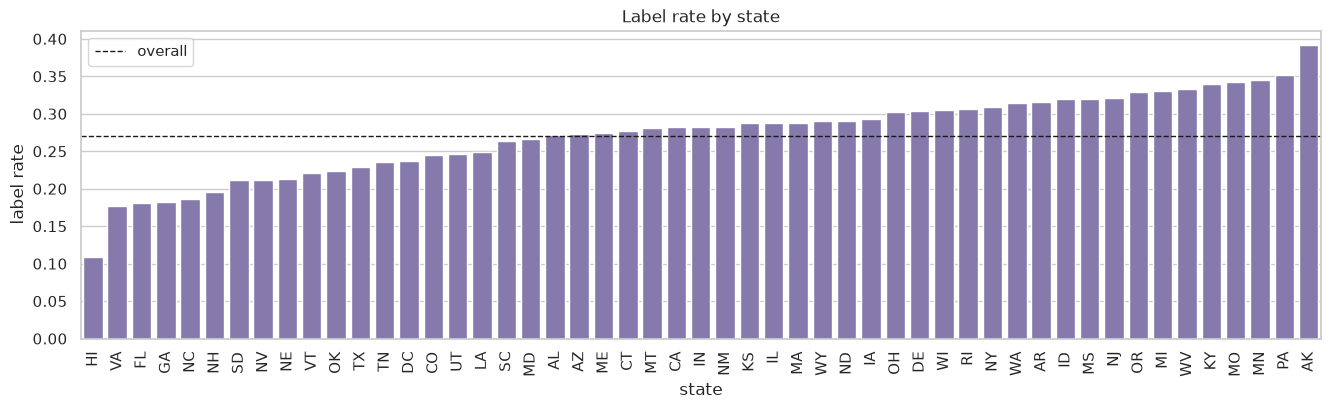

In [12]:
st = lab.groupby("state_abbr")["y"].mean().sort_values()
plt.figure(figsize=(16, 4))
sns.barplot(x=st.index, y=st.values, color="#8172B3")
plt.axhline(lab.y.mean(), color="k", ls="--", lw=1, label="overall")
plt.xticks(rotation=90); plt.xlabel("state"); plt.ylabel("label rate"); plt.title("Label rate by state"); plt.legend(); plt.show()

### 2.5 A seasonal-naive baseline

Since seasonality is so strong, a fair "dumb" baseline is: **did this county's rate rise over the same 3-month window last year?**
That is `rate(t−9) − rate(t−12)`, which only looks backward, so there's no leakage. It isn't added as a model feature here; it's
only a comparison score. If logistic regression can't clearly beat this, it's mostly learning the calendar.

In [13]:
df["m_idx"] = df.month.dt.year * 12 + df.month.dt.month
key = df[["county_fips", "m_idx", "f_rate"]]
n_before = len(df)
df = (df.merge(key.assign(m_idx=key.m_idx + 9).rename(columns={"f_rate": "rate_tm9"}), on=["county_fips", "m_idx"], how="left")
        .merge(key.assign(m_idx=key.m_idx + 12).rename(columns={"f_rate": "rate_tm12"}), on=["county_fips", "m_idx"], how="left"))
assert len(df) == n_before, "merge changed the row count"
df["seasonal_naive_delta"] = df.rate_tm9 - df.rate_tm12
lab = df[df["is_labeled"]].copy(); lab["y"] = lab["y_label"].astype(int)
ok = lab.seasonal_naive_delta.notna()
print(f"seasonal-naive available on {ok.mean():.1%} of labeled rows")
print(f"seasonal-naive ROC AUC (all labeled rows): {roc_auc_score(lab.y[ok], lab.seasonal_naive_delta[ok]):.3f}")

seasonal-naive available on 91.1% of labeled rows
seasonal-naive ROC AUC (all labeled rows): 0.809


## 3. Validation design: out-of-time test plus stratified, grouped k-fold

This is the most important modeling decision in the notebook.

**Why not a plain random stratified split?** Rows are not independent:
- The same county in neighboring months has nearly identical features, and its 3-month target windows **overlap**.
- Every county in the same month shares the same FRED values and the same national shock.

A random split puts March 2019 in training and April 2019 in validation, so the model gets graded on something it has nearly seen.
Scores come out optimistic.

**What we do instead**
1. **Out-of-time test set:** the newest 12 labeled months. Before it, a **3-month gap** is dropped so no training target window
   overlaps the test period. This mimics production: train on the past, predict the future. (A time-based test set can't also be
   stratified. Its positive rate is whatever really happened. That's realistic, and we report it.)
2. **Inside training: `StratifiedGroupKFold`** with **groups = calendar quarter**. Every row from the same quarter lands in the same
   fold (no near-duplicate months split across folds), and folds are **stratified** so each one has about the same positive rate.

**Why the 3-month ga?p**

The target looks forward: y_delta_3m = rate(t+3) − rate(t). Suppose training ran right up to test_start. A training row at test_start − 1 would have a label built from rate(test_start + 2), which is inside the test window. The model would then be trained on test-period outcomes, which is leakage.

With the gap, the last training month is lab_months[-16]. Its label uses the rate at lab_months[-13], which is still before the test window starts, so no training label sees test-period data. The gap length equals the label horizon of 3 months, which is the right size.

This also roughly matches real use. When you score month t, the newest month with a known outcome is about 3 months older than t.

In [14]:
lab_months = np.sort(lab.month.unique())
test_start, gap_start = lab_months[-12], lab_months[-15]
    # test start = most recent 12 month (12th month from the end)
    # gap start = 15th month from the end
    # This gap is necessary to prevent data leakage from the most recent months into the training set
train = lab[lab.month < gap_start].copy()
test = lab[lab.month >= test_start].copy()

split = pd.DataFrame({
    "rows": [len(train), len(test)],
    "from": [train.month.min(), test.month.min()], "to": [train.month.max(), test.month.max()],
    "positive_rate": [train.y.mean(), test.y.mean()]}, index=["train", "test"])
print(f"gap (dropped): {pd.Timestamp(gap_start):%Y-%m} to {pd.Timestamp(test_start) - pd.DateOffset(months=1):%Y-%m}")
split

gap (dropped): 2025-01 to 2025-03


,rows,from,to,positive_rate
train,377097,2015-01-01,2024-12-01,0.2732
test,37716,2025-04-01,2026-05-01,0.2884


**Tuning on a stratified subsample.** The training set has about 380k rows. A full grid search (30 settings × 5 folds = 150 fits of the
`saga` solver) on all of it is slow on this machine. We tune on a **stratified 60k-row subsample** (same positive rate as training).
That's plenty for about 26 coefficients. Then the chosen settings are **refit on the full training set** before testing.

In [15]:
X_cols = FEATURES
tune, _ = train_test_split(train, train_size=60_000, stratify=train.y, random_state=RNG)
X_tune, y_tune = tune[X_cols], tune.y.values
groups_tune = (tune.month.dt.year * 10 + tune.month.dt.quarter).values
X_train, y_train = train[X_cols], train.y.values
X_test, y_test = test[X_cols], test.y.values

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RNG)
folds = []
for k, (tr, va) in enumerate(cv.split(X_tune, y_tune, groups_tune)):
    folds.append({"fold": k, "train_rows": len(tr), "val_rows": len(va), "val_positive_rate": y_tune[va].mean(),
                  "val_quarters": len(np.unique(groups_tune[va])),
                  "quarters_shared_with_train": len(np.intersect1d(groups_tune[tr], groups_tune[va]))})
pd.DataFrame(folds)

,fold,train_rows,val_rows,val_positive_rate,val_quarters,quarters_shared_with_train
0,0,47928,12072,0.2527,8,0
1,1,48096,11904,0.2731,8,0
2,2,47965,12035,0.2557,8,0
3,3,47933,12067,0.2494,8,0
4,4,48078,11922,0.3358,8,0


The table confirms both properties: validation positive rates are close to each other (**stratified**), and
`quarters_shared_with_train` is 0 (**grouped**: no quarter is split between a fold's train and validation sides).

### 3.1 Why the tuning sample overlaps the training set, and why separating them would buy less than it looks

The 60k tuning rows are drawn *from* `train`, so after tuning, the final model is refit on all 377k training rows, **including those
60k**. A natural reaction is: "Shouldn't the tuning set be a separate body of data, removed from training?" That alternative was
considered. Here's why this notebook keeps the overlap.

**1. The tuning sample is for speed; the cross-validation does the validating.** A grid search is 30 settings × 5 folds = 150 fits.
On all 377k rows that's too slow, so the search runs on a 60k sample instead. Inside that sample, each fold fits on 4/5 and scores the
other 1/5, which acts as a mock holdout. Every tuning row is held out exactly once, so every score comes from rows the fold's model
didn't see. The tuning sample is a smaller copy of the training data, not a third data set.

**2. The overlap isn't leakage.** Leakage means information the model shouldn't have reaches the number you report. The number we report
comes from the **test year**, and the test year is never in `tune` or `train`. Choosing settings with CV and then refitting on all the
training data is the standard recipe. It only lets the final model learn from more rows.

**3. Removing the tuning rows from `train` would separate rows, not information.** Rows in this panel are near-copies of their neighbors:
- the same county in neighboring months has almost the same features,
- its 3-month target windows overlap (month *t* and *t+1* share 2 of their 3 months),
- and every county in a month shares the same FRED values and the same national shock.

Even if the 60k rows were deleted from `train`, a tuning row for, say, County X in March 2019 would still have County X in February and
April 2019 sitting in `train`, nearly identical. So the model would still have "seen" almost everything the tuning set contains. Meanwhile
the deletion would throw away about **16%** of the training data (60k of 377k).

**4. The real weakness is time, and separating the rows doesn't fix it.** The CV folds are grouped by quarter, so no quarter is split
between fit and validation. But the folds still **mix years**: a fold can fit on 2016–2023 and validate on 2019. Settings are graded
on economic regimes the model has already seen. That makes CV optimistic: **CV ROC AUC 0.842 vs. 0.799 on the test year** (§8). It also
favors flexible models most (notebook 02 shows kernel SVMs winning in CV and losing on the test year). A tuning set drawn from the same
years has this problem whether or not its rows are removed from training. The design that does fix it is an **out-of-time tuning
period**: fit on earlier years, tune on a later year (for example 2024, with a 3-month gap on each side), then test on the newest year.

**5. The fold-to-fold spread understates real uncertainty.** All five folds come from the same years, so the sd in §4 measures sampling
noise within those years. It doesn't measure how much performance moves from one year to the next, which is the uncertainty that matters
for a model scored on a new month.

**6. The threshold carries over.** The F1 threshold (§4.2) is a hyperparameter too: it's chosen from out-of-fold predictions on the
tuning sample, made by models fit on about 48k rows, then applied to the final model fit on 377k. Logistic regression's probabilities
mean the same thing at both sizes, so the threshold transfers well.

**Bottom line.** Keeping the tuning sample inside the training years is correct and standard: nothing from the test year leaks, and every
tuning score comes from held-out rows. Pulling those rows out of `train` would look stricter but would cost 16% of the training data and
change little, because the panel's rows are so similar to each other. The honest limitation is the one in point 4, which is why the
**out-of-time test year is the number to trust**, not CV.

## 4. Logistic regression: L2, L1, and elastic net

Logistic regression models $P(y=1 \mid x) = \sigma(w^\top x + b)$ and fits $w$ by minimizing **binary cross-entropy** plus a penalty:

$$\min_w \; \underbrace{-\frac{1}{n}\sum_i \big[y_i \log p_i + (1-y_i)\log(1-p_i)\big]}_{\text{binary cross-entropy (log loss)}} \;+\; \frac{1}{C}\Big(\rho\,\lVert w\rVert_1 + \tfrac{1-\rho}{2}\lVert w\rVert_2^2\Big)$$

| Penalty | `l1_ratio` (ρ) | What it does |
|---|---|---|
| **L2 (ridge)** | 0 | Shrinks all coefficients smoothly toward 0; handles correlated features by sharing weight between them. |
| **L1 (lasso)** | 1 | Pushes some coefficients to **exactly 0**, so it does feature selection. |
| **Elastic net** | 0 < ρ < 1 | A mix: some sparsity, but more stable than pure L1 with correlated features. |
| **None** | C = ∞ | Plain maximum likelihood, our reference point. |

**`C` is the inverse of regularization strength**: small `C` means a strong penalty and simpler models; large `C` means a weak penalty.
We use the `saga` solver because it's the one that supports all three penalties, so the comparison is like-for-like.
(scikit-learn ≥ 1.8 sets the penalty type with `l1_ratio` directly; the old `penalty=` argument is deprecated.)

In [16]:
def make_lr(**kw):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("lr", LogisticRegression(solver="saga", max_iter=3000, tol=1e-3, random_state=RNG, **kw)),
    ])

param_grid = {"lr__C": np.logspace(-4, 1, 6), "lr__l1_ratio": [0.0, 0.25, 0.5, 0.75, 1.0]}
scoring = {"log_loss": "neg_log_loss", "roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1", "accuracy": "accuracy"}

search = GridSearchCV(make_lr(), param_grid, scoring=scoring, refit="log_loss", cv=cv, n_jobs=-1, return_train_score=True)
t0 = time.time()
search.fit(X_tune, y_tune, groups=groups_tune)
print(f"{len(search.cv_results_['params']) * cv.get_n_splits()} fits in {time.time() - t0:.0f}s")
print("best params (by CV log loss):", search.best_params_)
print(f"best CV log loss: {-search.best_score_:.4f}")

150 fits in 464s
best params (by CV log loss): {'lr__C': np.float64(0.1), 'lr__l1_ratio': 0.25}
best CV log loss: 0.4903


**Why tune on log loss (= binary cross-entropy) instead of accuracy or F1?** Log loss scores the *probabilities*, not just a 0/1
decision at some threshold. It's the quantity logistic regression actually optimizes, it's smooth, and it rewards calibrated
probabilities, which matters because the map will show a *score*, and the red/not-red threshold can be chosen separately.

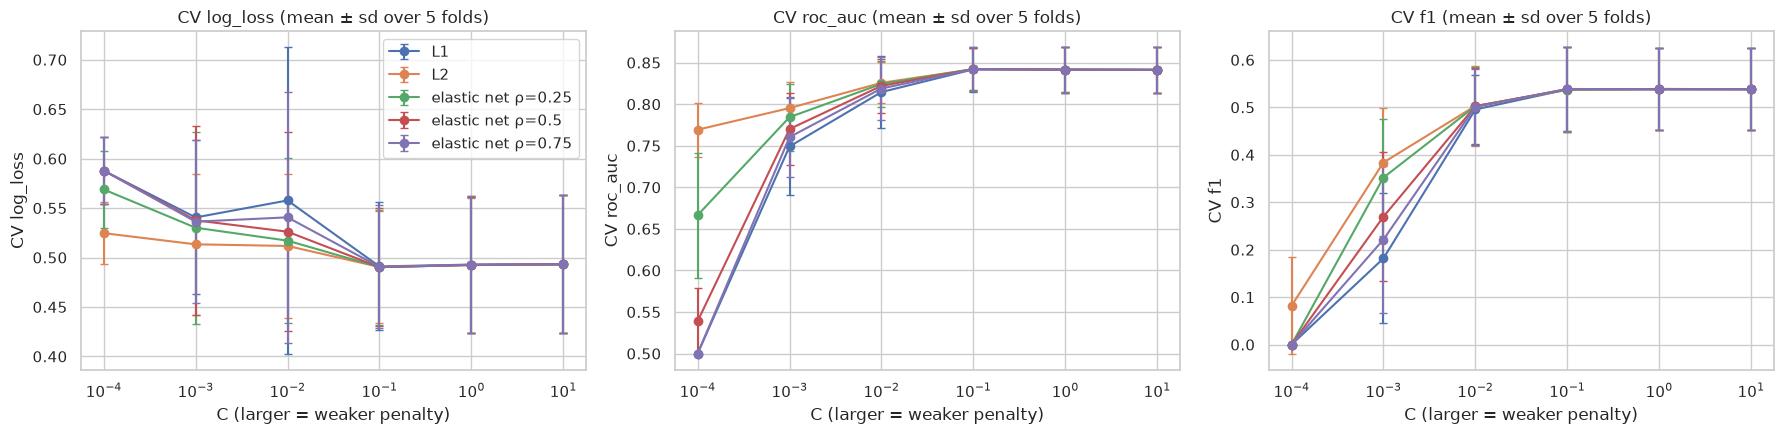

,penalty,C,cv_log_loss,cv_log_loss_sd,cv_roc_auc,cv_pr_auc,cv_f1,cv_accuracy
16,elastic net ρ=0.25,0.1000,0.4903,0.0580,0.8422,0.6460,0.5374,0.7849
17,elastic net ρ=0.5,0.1000,0.4903,0.0599,0.8422,0.6457,0.5384,0.7856
15,L2,0.1000,0.4905,0.0564,0.8421,0.6461,0.5369,0.7845
18,elastic net ρ=0.75,0.1000,0.4905,0.0621,0.8421,0.6451,0.5386,0.7861
19,L1,0.1000,0.4910,0.0647,0.8419,0.6442,0.5377,0.7860


In [17]:
res = pd.DataFrame(search.cv_results_)
res["C"] = res.param_lr__C.astype(float); res["l1_ratio"] = res.param_lr__l1_ratio.astype(float)
res["penalty"] = res.l1_ratio.map({0.0: "L2", 1.0: "L1"}).fillna("elastic net ρ=" + res.l1_ratio.astype(str))
for m in scoring:
    res[f"cv_{m}"] = res[f"mean_test_{m}"] * (-1 if m == "log_loss" else 1)
    res[f"cv_{m}_sd"] = res[f"std_test_{m}"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, m in zip(axes, ["log_loss", "roc_auc", "f1"]):
    for pen, g in res.groupby("penalty"):
        ax.errorbar(g.C, g[f"cv_{m}"], yerr=g[f"cv_{m}_sd"], marker="o", capsize=3, label=pen)
    ax.set_xscale("log"); ax.set_xlabel("C (larger = weaker penalty)"); ax.set_ylabel(f"CV {m}"); ax.set_title(f"CV {m} (mean ± sd over 5 folds)")
axes[0].legend(); plt.tight_layout(); plt.show()

best_per_penalty = res.loc[res.groupby("penalty").cv_log_loss.idxmin(),
                           ["penalty", "C", "cv_log_loss", "cv_log_loss_sd", "cv_roc_auc", "cv_pr_auc", "cv_f1", "cv_accuracy"]]
best_per_penalty.sort_values("cv_log_loss")

**How to read this.** On the left, as `C` shrinks (left side), every penalty eventually over-regularizes and log loss gets worse.
With very small `C`, L1 shrinks every coefficient to zero and predicts the base rate. On the right side all penalties converge,
because with weak regularization they're all close to plain logistic regression. The useful comparison is the **best point of each
curve** (table above). With only about 26 features and tens of thousands of rows, overfitting isn't a big risk, so the penalties
usually end up close. The error bars (fold-to-fold sd) show whether a difference is real or noise.

### 4.1 Coefficients and the L1 path

The **L1 regularization path** refits L1 logistic regression across `C` and tracks each standardized coefficient. Reading right to
left (stronger penalty), features drop to exactly zero one by one. **The last ones standing are the most important.**

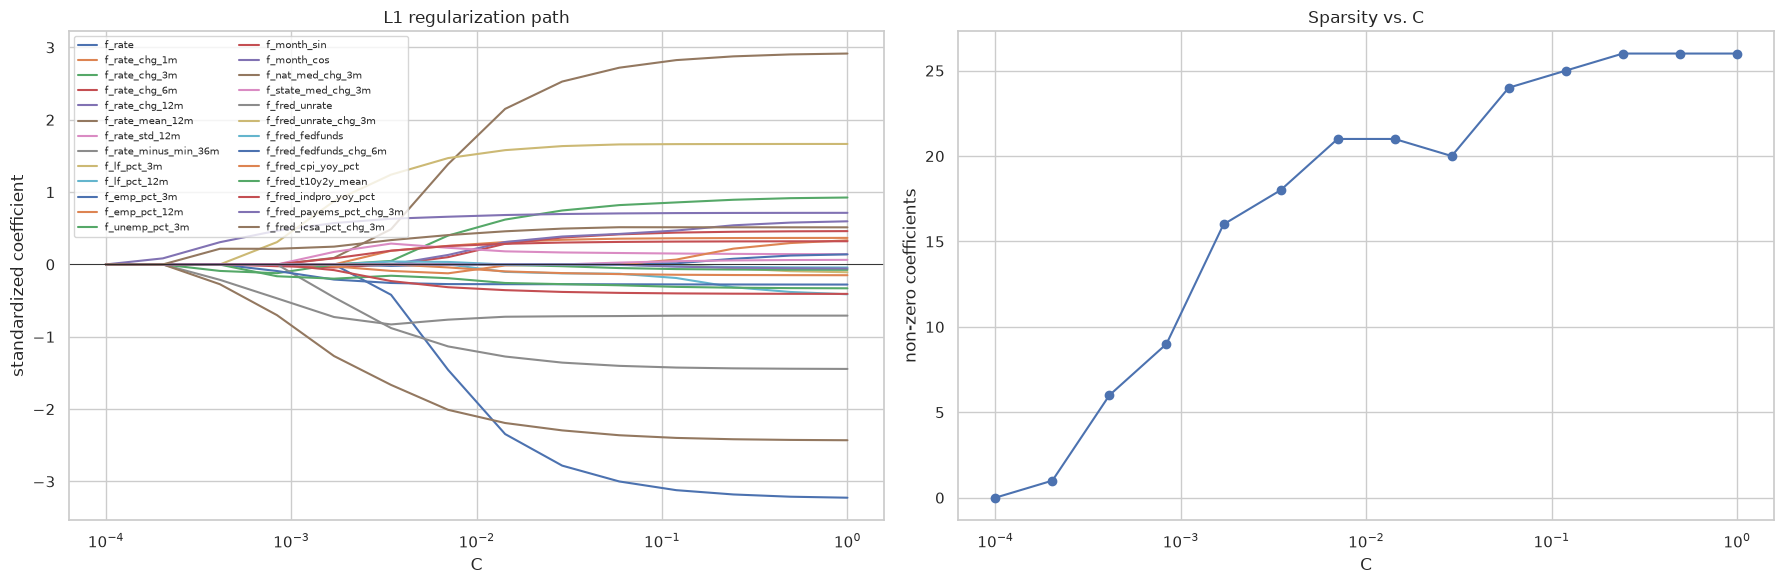

C at which each feature first becomes non-zero (smaller = more important):


f_month_cos              0.0002
f_rate_minus_min_36m     0.0004
f_unemp_pct_3m           0.0004
f_nat_med_chg_3m         0.0004
f_fred_icsa_pct_chg_3m   0.0004
f_fred_t10y2y_mean       0.0004
f_rate_chg_6m            0.0008
f_fred_fedfunds_chg_6m   0.0008
f_fred_unrate_chg_3m     0.0008
f_month_sin              0.0017
dtype: float64

In [18]:
Cs_path = np.logspace(-4, 0, 14)
path = []
for C in Cs_path:
    m = make_lr(C=C, l1_ratio=1.0).fit(X_tune, y_tune)
    path.append(m.named_steps["lr"].coef_.ravel())
path = pd.DataFrame(path, index=Cs_path, columns=X_cols)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for col in X_cols:
    axes[0].plot(path.index, path[col], label=col)
axes[0].set_xscale("log"); axes[0].set_xlabel("C"); axes[0].set_ylabel("standardized coefficient")
axes[0].set_title("L1 regularization path"); axes[0].axhline(0, color="k", lw=0.6)
axes[0].legend(fontsize=7, ncol=2, loc="upper left")
axes[1].plot(path.index, (path.abs() > 1e-8).sum(axis=1), marker="o")
axes[1].set_xscale("log"); axes[1].set_xlabel("C"); axes[1].set_ylabel("non-zero coefficients"); axes[1].set_title("Sparsity vs. C")
plt.tight_layout(); plt.show()

first_in = (path.abs() > 1e-8).idxmax().where((path.abs() > 1e-8).any()).sort_values()
print("C at which each feature first becomes non-zero (smaller = more important):")
first_in.head(10)

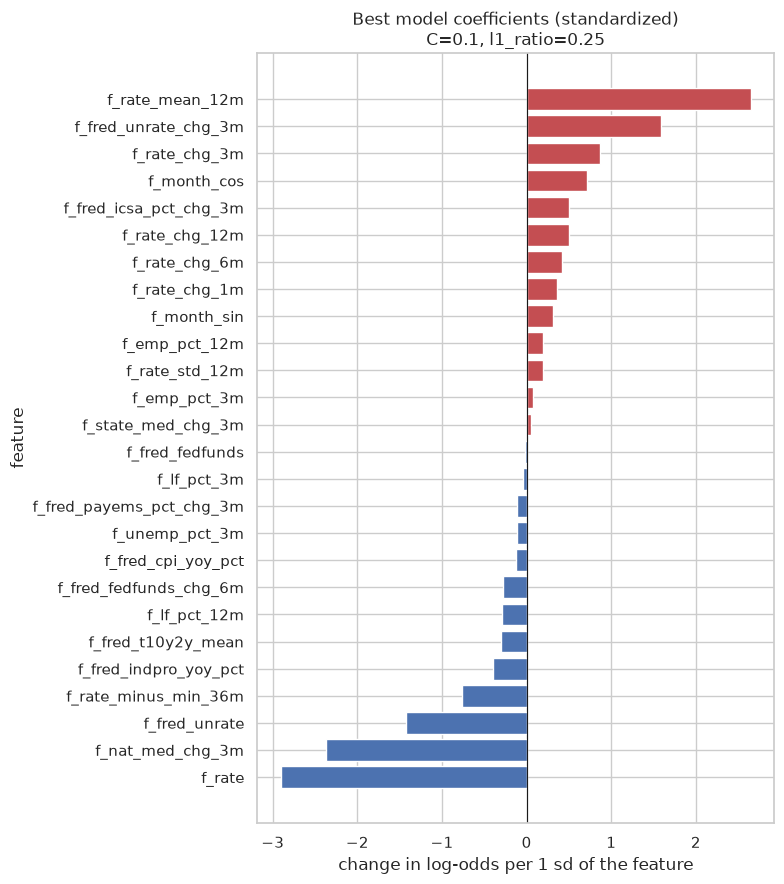

In [19]:
best_lr = search.best_estimator_
coef = pd.Series(best_lr.named_steps["lr"].coef_.ravel(), index=X_cols).sort_values()
plt.figure(figsize=(8, 9))
plt.barh(coef.index, coef.values, color=np.where(coef > 0, "#C44E52", "#4C72B0"))
plt.axvline(0, color="k", lw=0.8)
plt.title(f"Best model coefficients (standardized)\nC={search.best_params_['lr__C']:g}, l1_ratio={search.best_params_['lr__l1_ratio']}")
plt.xlabel("change in log-odds per 1 sd of the feature"); plt.ylabel("feature"); plt.tight_layout(); plt.show()

**Interpreting coefficients.** Because inputs are standardized, each bar is the change in **log-odds** of a ≥ 0.5 pp rise when that
feature goes up by one standard deviation, holding the others fixed. Exponentiate to get an odds ratio (e.g. +0.5 → ×1.65 odds).
With correlated features, read coefficients as a group: two correlated features may split weight or even take opposite signs.

### 4.2 Choosing a decision threshold (without touching the test set)

The model outputs probabilities. To get a confusion matrix, precision, recall, and F1, we need a cutoff. 0.5 is arbitrary for a
27%-positive problem. We choose the threshold that **maximizes F1 on out-of-fold CV predictions** from the training subsample, so the
test set stays untouched for the final, honest evaluation.

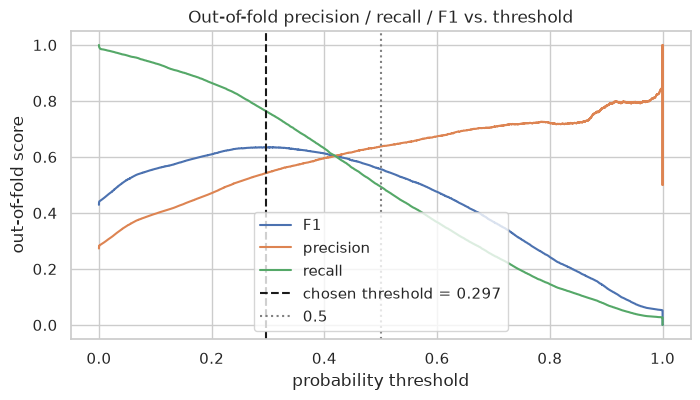

OOF log loss 0.4902 | OOF ROC AUC 0.8257 | best OOF F1 0.6347 at threshold 0.297


In [20]:
oof = cross_val_predict(best_lr, X_tune, y_tune, cv=cv, groups=groups_tune, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_tune, oof)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
THR = float(thr[np.argmax(f1s)])

plt.figure(figsize=(8, 4))
plt.plot(thr, f1s, label="F1"); plt.plot(thr, prec[:-1], label="precision"); plt.plot(thr, rec[:-1], label="recall")
plt.axvline(THR, color="k", ls="--", label=f"chosen threshold = {THR:.3f}")
plt.axvline(0.5, color="gray", ls=":", label="0.5")
plt.xlabel("probability threshold"); plt.ylabel("out-of-fold score"); plt.title("Out-of-fold precision / recall / F1 vs. threshold"); plt.legend(); plt.show()
print(f"OOF log loss {log_loss(y_tune, oof):.4f} | OOF ROC AUC {roc_auc_score(y_tune, oof):.4f} | best OOF F1 {f1s.max():.4f} at threshold {THR:.3f}")

**Trade-off.** Lowering the threshold flags more counties: recall rises (we catch more real rises), precision falls (more false alarms).
For an early-warning map, the right point depends on the cost of a missed rise versus a false alarm. F1 is a neutral default that
weights them equally.

## 5. Final evaluation on the out-of-time test year

Now the chosen models are **refit on the full training set** and scored once on the test year. Compared:
- **Dummy (prior):** always predicts the training positive rate. This sets the floor for log loss and AUC (AUC = 0.5).
- **Seasonal-naive rule:** flag if last year's same-window change was ≥ 0.5 pp. (It produces no probabilities, so there's no log loss.)
- **Unpenalized LR:** C = ∞, the reference.
- **Best L2, best L1, best elastic net:** each penalty's best `C` from CV.

**Metrics**
- **Log loss / binary cross-entropy:** quality of the probabilities (lower is better). They are the same quantity; §5.1 checks this numerically.
- **ROC AUC:** the probability that a random positive gets a higher score than a random negative. It doesn't depend on the threshold.
- **PR AUC (average precision):** like AUC, but focused on the positive class. More informative when positives are the minority. The chance level is the positive rate, not 0.5.
- **Brier score:** mean squared error of the probabilities.
- **Accuracy, precision, recall, F1:** depend on the threshold; computed at the CV-chosen threshold.

In [21]:
def evaluate(name, y_true, p=None, yhat=None, thr=None):
    if yhat is None:
        yhat = (p >= thr).astype(int)
    out = {"model": name, "threshold": thr,
           "log_loss": log_loss(y_true, p) if p is not None else np.nan,
           "brier": brier_score_loss(y_true, p) if p is not None else np.nan,
           "roc_auc": roc_auc_score(y_true, p) if p is not None else np.nan,
           "pr_auc": average_precision_score(y_true, p) if p is not None else np.nan,
           "accuracy": accuracy_score(y_true, yhat), "precision": precision_score(y_true, yhat, zero_division=0),
           "recall": recall_score(y_true, yhat), "f1": f1_score(y_true, yhat)}
    return out

fitted, probs, rows = {}, {}, []

dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
probs["Dummy (prior)"] = dummy.predict_proba(X_test)[:, 1]
rows.append(evaluate("Dummy (prior)", y_test, probs["Dummy (prior)"], thr=0.5))

sn = test.seasonal_naive_delta.fillna(0).values
rows.append(evaluate("Seasonal-naive rule", y_test, yhat=(sn >= 0.5).astype(int)))

unpen = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                  ("lr", LogisticRegression(C=np.inf, solver="lbfgs", max_iter=2000))]).fit(X_train, y_train)
probs["LR unpenalized"] = unpen.predict_proba(X_test)[:, 1]
rows.append(evaluate("LR unpenalized", y_test, probs["LR unpenalized"], thr=THR))

t0 = time.time()
for _, r in best_per_penalty.iterrows():
    name = f"LR {r.penalty} (C={r.C:g})"
    l1r = res.loc[(res.penalty == r.penalty)].l1_ratio.iloc[0]
    fitted[name] = make_lr(C=r.C, l1_ratio=l1r).fit(X_train, y_train)
    probs[name] = fitted[name].predict_proba(X_test)[:, 1]
    rows.append(evaluate(name, y_test, probs[name], thr=THR))
print(f"refit {len(best_per_penalty)} penalized models on {len(X_train):,} rows in {time.time() - t0:.0f}s")

results = pd.DataFrame(rows).set_index("model")
results.style.format("{:.4f}", na_rep="–").highlight_min(subset=["log_loss", "brier"], color="#d4edda").highlight_max(subset=["roc_auc", "pr_auc", "f1", "accuracy"], color="#d4edda")

refit 5 penalized models on 377,097 rows in 566s


,threshold,log_loss,brier,roc_auc,pr_auc,accuracy,precision,recall,f1
model,,,,,,,,,
Dummy (prior),0.5000,0.6013,0.2055,0.5000,0.2884,0.7116,0.0000,0.0000,0.0000
Seasonal-naive rule,–,–,–,–,–,0.7940,0.6247,0.7156,0.6671
LR unpenalized,0.2969,0.4975,0.1629,0.7991,0.6432,0.7672,0.5981,0.5875,0.5927
LR L1 (C=0.1),0.2969,0.4975,0.1630,0.7990,0.6436,0.7666,0.5972,0.5862,0.5916
LR L2 (C=0.1),0.2969,0.4978,0.1631,0.7985,0.6430,0.7657,0.5953,0.5864,0.5908
LR elastic net ρ=0.25 (C=0.1),0.2969,0.4977,0.1631,0.7986,0.6432,0.7660,0.5958,0.5862,0.5909
LR elastic net ρ=0.5 (C=0.1),0.2969,0.4976,0.1630,0.7987,0.6433,0.7663,0.5964,0.5860,0.5912
LR elastic net ρ=0.75 (C=0.1),0.2969,0.4976,0.1630,0.7989,0.6435,0.7665,0.5970,0.5861,0.5915


### 5.1 Binary cross-entropy is log loss

Computing BCE from its formula with numpy gives the same number as `sklearn.metrics.log_loss`.

In [22]:
best_name = min((k for k in probs if k.startswith("LR ") and "unpen" not in k), key=lambda k: results.loc[k, "log_loss"])
p = np.clip(probs[best_name], 1e-15, 1 - 1e-15)
bce = -np.mean(y_test * np.log(p) + (1 - y_test) * np.log(1 - p))
print(f"best penalized model on test: {best_name}")
print(f"numpy BCE = {bce:.6f}   sklearn log_loss = {log_loss(y_test, probs[best_name]):.6f}")

best penalized model on test: LR L1 (C=0.1)
numpy BCE = 0.497511   sklearn log_loss = 0.497511


### 5.2 ROC and precision–recall curves

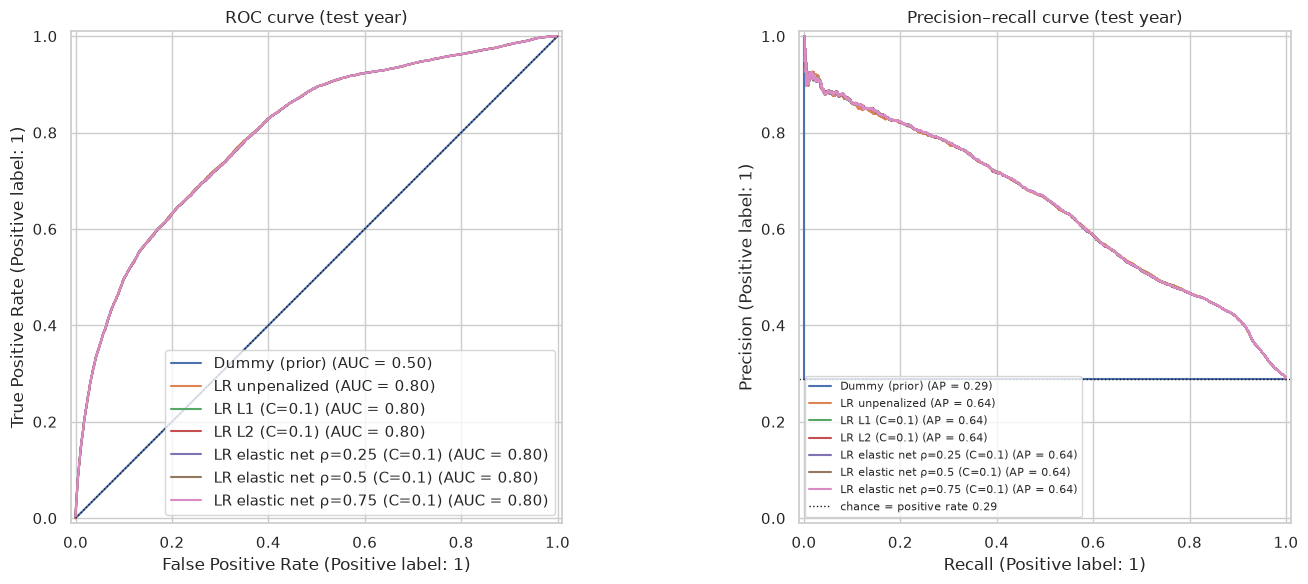

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name, p in probs.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, p, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set_title("ROC curve (test year)")
axes[1].axhline(y_test.mean(), color="k", ls=":", lw=1, label=f"chance = positive rate {y_test.mean():.2f}")
axes[1].set_title("Precision–recall curve (test year)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading the curves.** The ROC curve plots the true-positive rate against the false-positive rate as the threshold moves. A curve
hugging the top-left corner is better, and the diagonal is random. The PR curve shows the precision you keep as you push recall up.
It's the more honest picture for an early-warning list, because it answers "of the counties we flag, how many actually rise?"
When the penalized curves lie on top of each other, the choice of penalty barely matters for ranking.

### 5.3 Confusion matrices: threshold 0.5 vs. the CV-chosen threshold

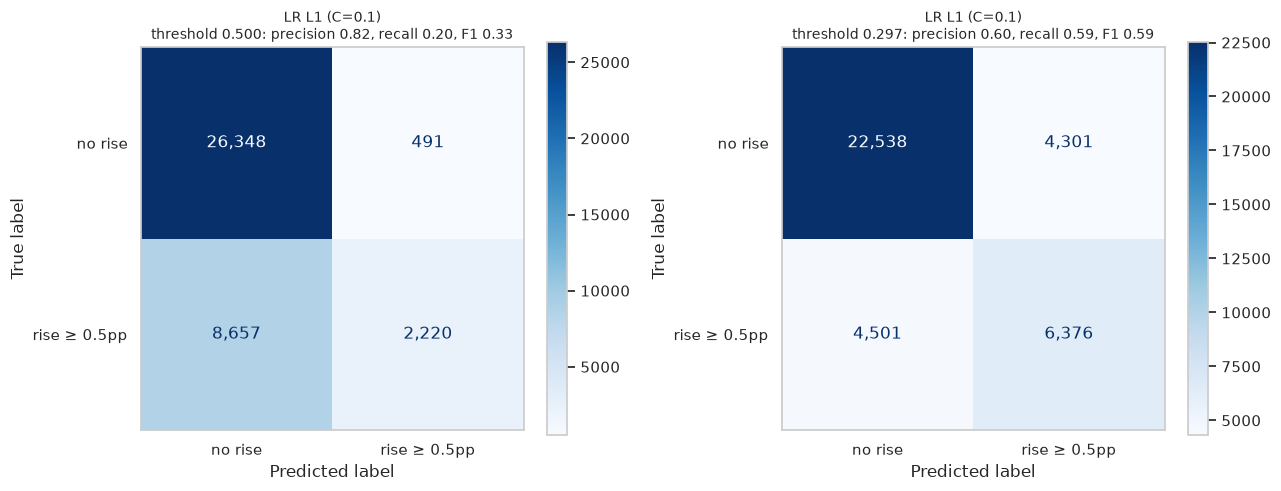

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, t in zip(axes, [0.5, THR]):
    yhat = (probs[best_name] >= t).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, yhat, normalize=None), display_labels=["no rise", "rise ≥ 0.5pp"]).plot(ax=ax, cmap="Blues", values_format=",")
    ax.set_title(f"{best_name}\nthreshold {t:.3f}: precision {precision_score(y_test, yhat):.2f}, recall {recall_score(y_test, yhat):.2f}, F1 {f1_score(y_test, yhat):.2f}", fontsize=10)
    ax.grid(False)
plt.tight_layout(); plt.show()

**Significance.** At 0.5 the model is conservative: few flags and high precision, but it misses many real rises (low recall). The
F1-tuned threshold flags more counties and trades some precision for much higher recall. Neither is "correct"; it's a policy choice
about false alarms versus misses. The threshold was picked on training-CV predictions, so these test numbers are honest.

### 5.4 Calibration: can the probabilities be taken literally?

A calibrated model's "30%" counties should rise about 30% of the time. Points on the diagonal mean the scores can be read as probabilities.
A shift between train and test years (a different economic regime) usually shows up here first.

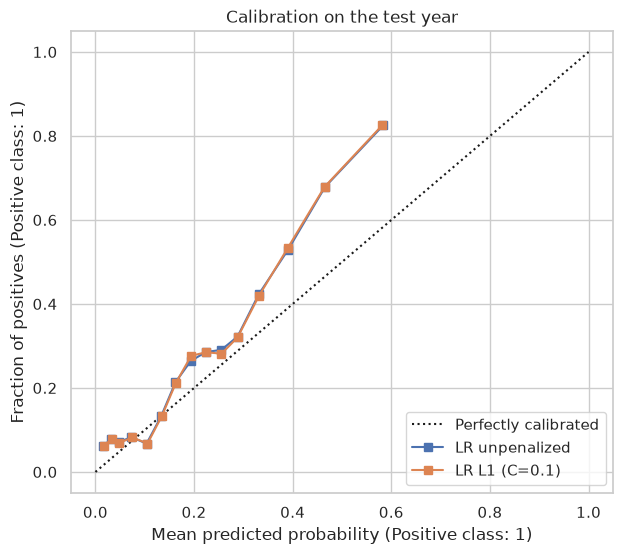

In [25]:
fig, ax = plt.subplots(figsize=(7, 6))
for name in ["LR unpenalized", best_name]:
    CalibrationDisplay.from_predictions(y_test, probs[name], n_bins=15, strategy="quantile", name=name, ax=ax)
ax.set_title("Calibration on the test year"); plt.show()

### 5.5 Stability over the test year, and the COVID question

Pooled metrics can hide month-to-month variation. Below is ROC AUC per test month, plus a check: **does training without 2020–2021
(the COVID years) change test performance?** Those months are extreme and could distort coefficients for normal times.

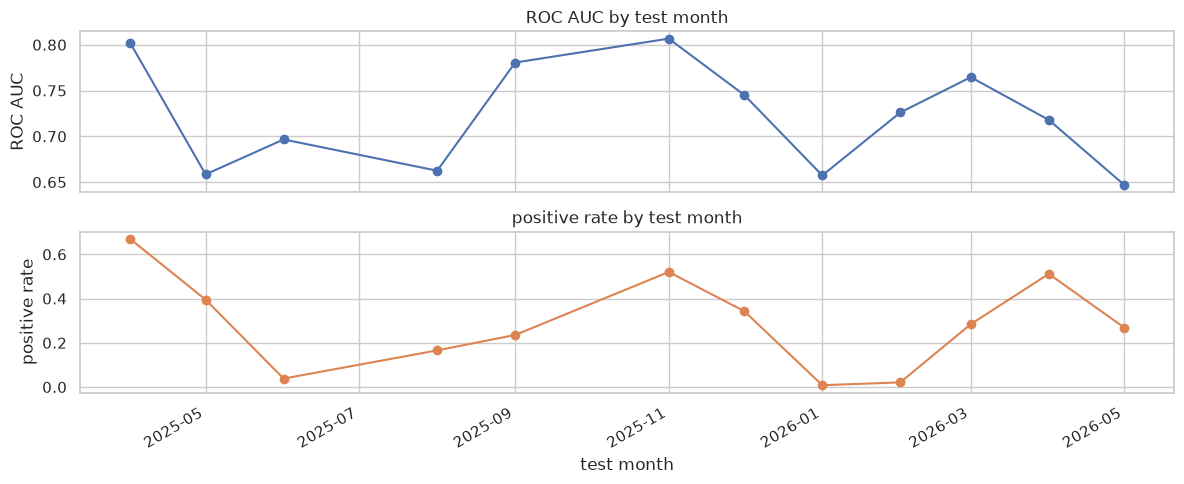

,threshold,log_loss,brier,roc_auc,pr_auc,accuracy,precision,recall,f1
model,,,,,,,,,
"CV-best params, all train years",0.2969,0.4977,0.1631,0.7986,0.6432,0.7660,0.5958,0.5862,0.5909
"CV-best params, train without 2020–21",0.2969,0.4639,0.1450,0.8270,0.6682,0.7629,0.5709,0.7164,0.6354


In [26]:
per_month = (test.assign(p=probs[best_name]).groupby("month")
             .apply(lambda g: pd.Series({"roc_auc": roc_auc_score(g.y, g.p) if g.y.nunique() > 1 else np.nan, "positive_rate": g.y.mean()}), include_groups=False))
ax = per_month.plot(subplots=True, figsize=(12, 5), marker="o", legend=False, title=["ROC AUC by test month", "positive rate by test month"])
ax[0].set_ylabel("ROC AUC"); ax[1].set_ylabel("positive rate"); ax[1].set_xlabel("test month")
plt.tight_layout(); plt.show()

best_C, best_l1 = search.best_params_["lr__C"], search.best_params_["lr__l1_ratio"]
no_covid = ~train.month.dt.year.isin([2020, 2021])
m_nc = make_lr(C=best_C, l1_ratio=best_l1).fit(X_train[no_covid], y_train[no_covid])
p_nc = m_nc.predict_proba(X_test)[:, 1]
p_all = make_lr(C=best_C, l1_ratio=best_l1).fit(X_train, y_train).predict_proba(X_test)[:, 1]
pd.DataFrame([evaluate("CV-best params, all train years", y_test, p_all, thr=THR),
              evaluate("CV-best params, train without 2020–21", y_test, p_nc, thr=THR)]).set_index("model")

## 6. PCA: does compressing the features help?

**Principal component analysis** rotates the standardized features into uncorrelated directions (components), ordered by how much
variance they explain. Keeping the first *k* components gives a lower-dimensional version of the data.

Why it might help: many features are correlated (rate changes over 1, 3, 6, and 12 months; several macro series), and PCA collapses
those blocks, which can stabilize coefficients. Why it might hurt: PCA is **unsupervised**. It keeps directions with high *variance*,
not directions that predict `y`. A low-variance direction can carry the signal and get dropped.

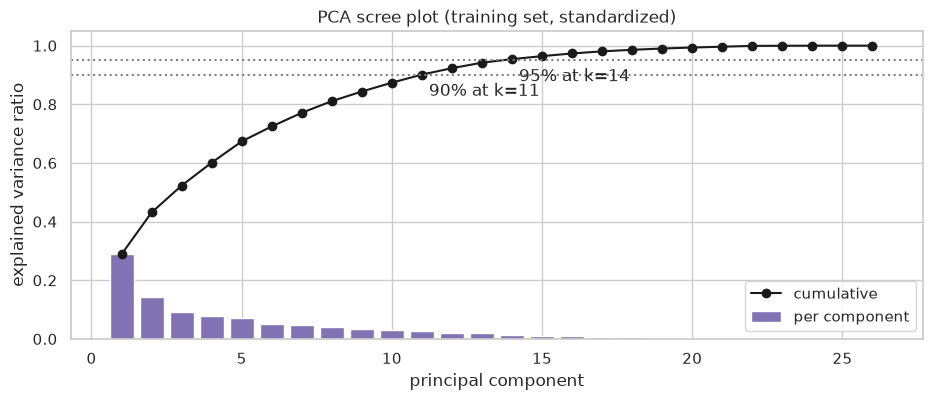

components for 90% variance: 11 of 26; for 95%: 14


In [27]:
prep = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit(X_train)
Z_train = prep.transform(X_train)
pca_full = PCA(random_state=RNG).fit(Z_train)
evr = pca_full.explained_variance_ratio_; cum = np.cumsum(evr)
k90, k95 = int(np.searchsorted(cum, 0.90) + 1), int(np.searchsorted(cum, 0.95) + 1)

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(1, len(evr) + 1), evr, color="#8172B3", label="per component")
ax.plot(range(1, len(evr) + 1), cum, "o-", color="k", label="cumulative")
for k, lvl in [(k90, 0.9), (k95, 0.95)]:
    ax.axhline(lvl, ls=":", color="gray"); ax.annotate(f"{lvl:.0%} at k={k}", (k, lvl), xytext=(5, -15), textcoords="offset points")
ax.set_xlabel("principal component"); ax.set_ylabel("explained variance ratio"); ax.set_title("PCA scree plot (training set, standardized)")
ax.legend(); plt.show()
print(f"components for 90% variance: {k90} of {len(X_cols)}; for 95%: {k95}")

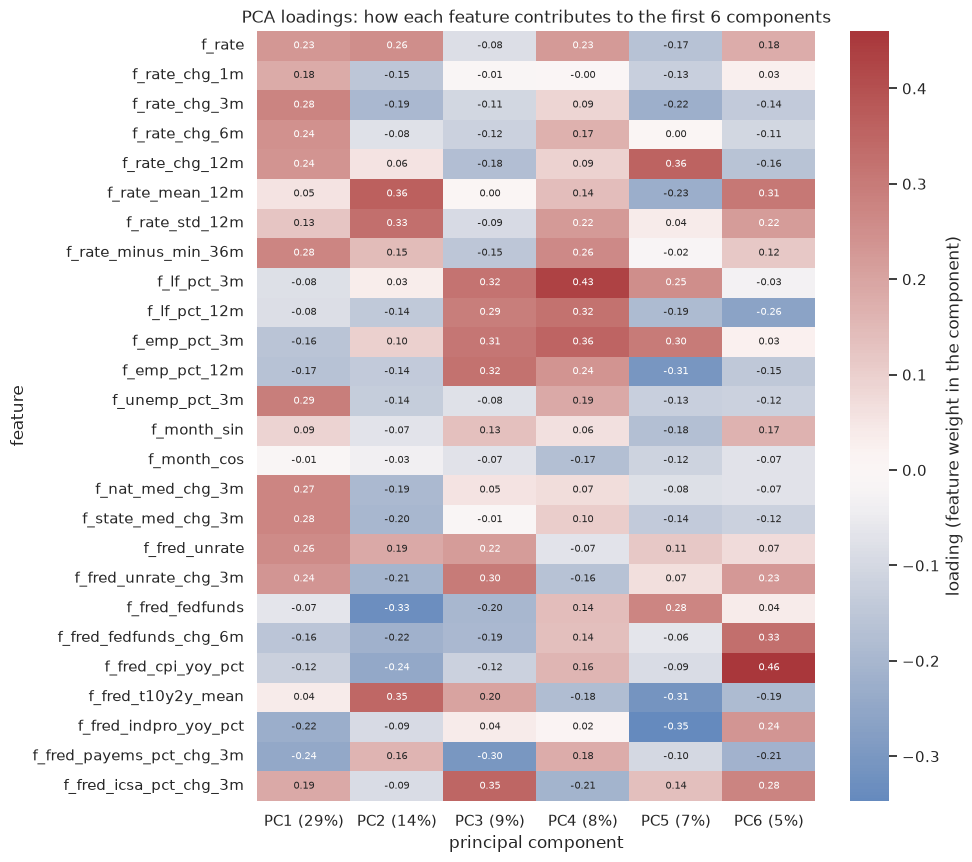

In [28]:
load = pd.DataFrame(pca_full.components_[:6].T, index=X_cols, columns=[f"PC{i+1} ({evr[i]:.0%})" for i in range(6)])
plt.figure(figsize=(9, 10))
sns.heatmap(load, cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"label": "loading (feature weight in the component)"})
plt.title("PCA loadings: how each feature contributes to the first 6 components"); plt.xlabel("principal component"); plt.ylabel("feature"); plt.show()

**Reading the loadings.** Each column is a component; large positive or negative values show which features define it. Typically
one component is "macro regime" (FRED series together), another is "recent local rate momentum" (the rate-change features), and
another is the seasonal sin/cos pair. Naming components this way is how you check that PCA found economically meaningful structure.

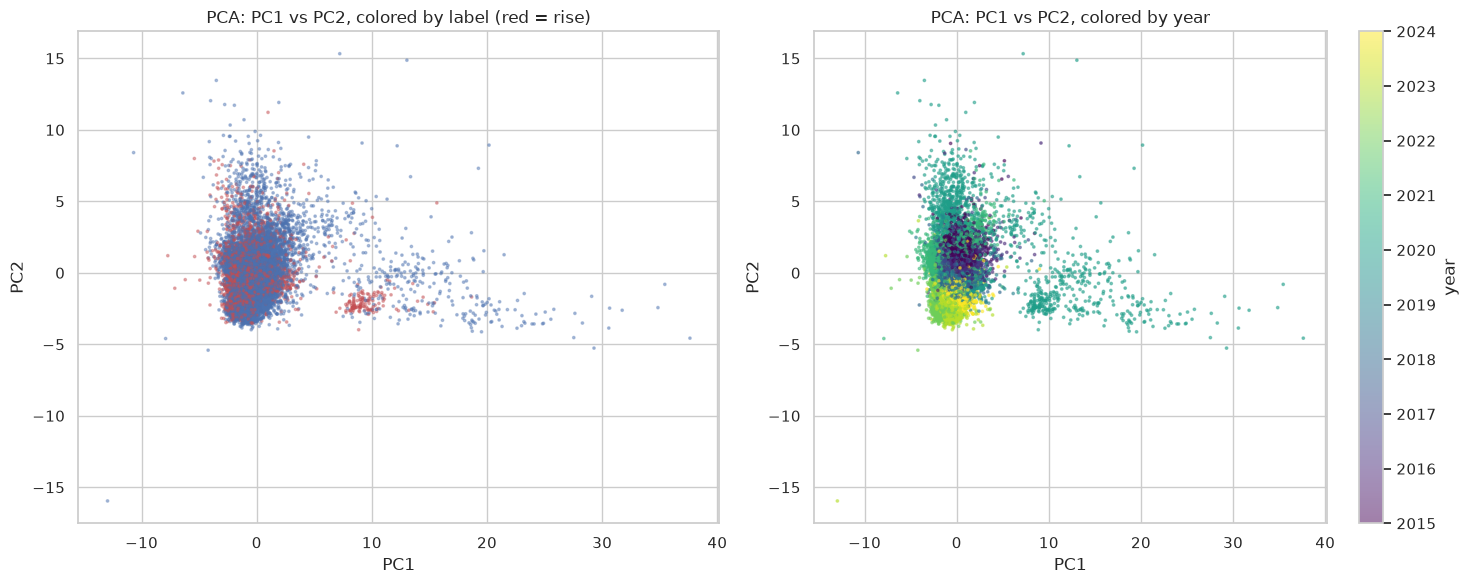

In [29]:
viz_idx = np.random.default_rng(RNG).choice(len(train), 15_000, replace=False)
Z_viz = Z_train[viz_idx]; y_viz = y_train[viz_idx]; yr_viz = train.month.dt.year.values[viz_idx]
P2 = pca_full.transform(Z_viz)[:, :2]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].scatter(P2[:, 0], P2[:, 1], c=np.where(y_viz == 1, "#C44E52", "#4C72B0"), s=3, alpha=0.4)
axes[0].set_title("PCA: PC1 vs PC2, colored by label (red = rise)")
sc = axes[1].scatter(P2[:, 0], P2[:, 1], c=yr_viz, s=3, alpha=0.5, cmap="viridis")
plt.colorbar(sc, ax=axes[1], label="year"); axes[1].set_title("PCA: PC1 vs PC2, colored by year")
for ax in axes: ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

**What the scatter shows.** If the red and blue points overlap heavily in 2D, the classes are **not linearly separable in the
top-variance directions**. That's expected: the target is a noisy future event. The year coloring usually shows PC1/PC2 tracking the
**macro regime** (COVID years separate clearly), which is variance that's shared by all counties in a month, not county-specific risk.

Next, PCA goes *inside* the pipeline (impute → scale → PCA → LR), and the number of components is tuned with the same stratified grouped CV.

done in 27s; best: {'lr__C': 0.1, 'pca__n_components': 26}, CV log loss 0.4885


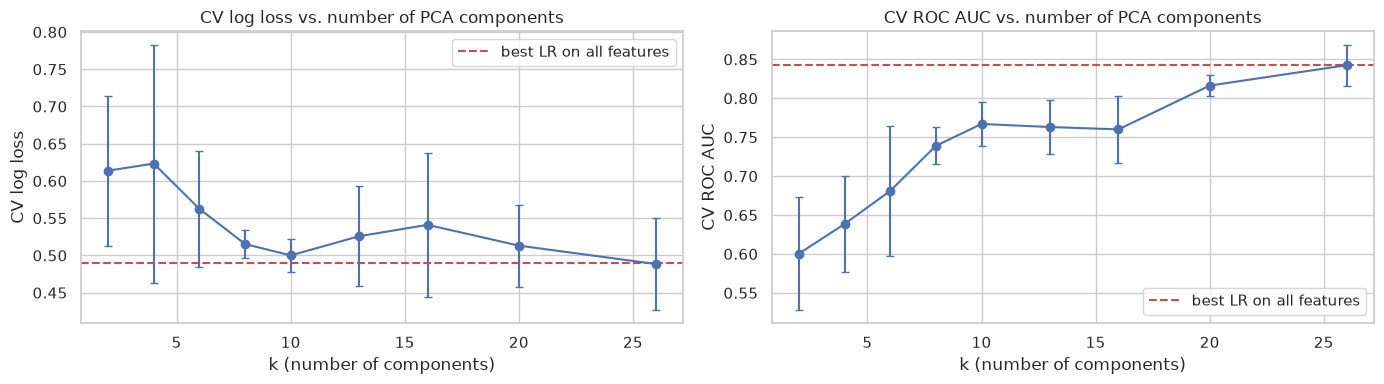

In [30]:
pca_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                     ("pca", PCA(random_state=RNG)), ("lr", LogisticRegression(solver="lbfgs", max_iter=2000))])
pca_grid = {"pca__n_components": [2, 4, 6, 8, 10, 13, 16, 20, len(X_cols)], "lr__C": [1e-3, 1e-2, 1e-1, 1.0]}
pca_search = GridSearchCV(pca_pipe, pca_grid, scoring=scoring, refit="log_loss", cv=cv, n_jobs=-1)
t0 = time.time(); pca_search.fit(X_tune, y_tune, groups=groups_tune)
print(f"done in {time.time() - t0:.0f}s; best: {pca_search.best_params_}, CV log loss {-pca_search.best_score_:.4f}")

pr = pd.DataFrame(pca_search.cv_results_)
pr["k"] = pr.param_pca__n_components.astype(int); pr["C"] = pr.param_lr__C.astype(float)
best_by_k = pr.loc[pr.groupby("k").mean_test_log_loss.idxmax()]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].errorbar(best_by_k.k, -best_by_k.mean_test_log_loss, yerr=best_by_k.std_test_log_loss, marker="o", capsize=3)
axes[0].axhline(best_per_penalty.cv_log_loss.min(), color="#C44E52", ls="--", label="best LR on all features")
axes[0].set_title("CV log loss vs. number of PCA components"); axes[0].set_xlabel("k (number of components)"); axes[0].set_ylabel("CV log loss"); axes[0].legend()
axes[1].errorbar(best_by_k.k, best_by_k.mean_test_roc_auc, yerr=best_by_k.std_test_roc_auc, marker="o", capsize=3)
axes[1].axhline(best_per_penalty.cv_roc_auc.max(), color="#C44E52", ls="--", label="best LR on all features")
axes[1].set_title("CV ROC AUC vs. number of PCA components"); axes[1].set_xlabel("k (number of components)"); axes[1].set_ylabel("CV ROC AUC"); axes[1].legend()
plt.tight_layout(); plt.show()

In [31]:
pca_rows = []
for k in [k90, k95]:
    C_k = best_by_k.set_index("k").C.get(k, pca_search.best_params_["lr__C"]) if k in best_by_k.k.values else pca_search.best_params_["lr__C"]
    m = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                  ("pca", PCA(n_components=k, random_state=RNG)), ("lr", LogisticRegression(C=C_k, max_iter=2000))]).fit(X_train, y_train)
    probs[f"PCA k={k} + LR"] = m.predict_proba(X_test)[:, 1]
    pca_rows.append(evaluate(f"PCA k={k} ({cum[k-1]:.0%} var) + LR", y_test, probs[f"PCA k={k} + LR"], thr=THR))
m = pca_search.best_estimator_.fit(X_train, y_train)
probs["PCA (CV-best k) + LR"] = m.predict_proba(X_test)[:, 1]
pca_rows.append(evaluate(f"PCA CV-best k={pca_search.best_params_['pca__n_components']} + LR", y_test, probs["PCA (CV-best k) + LR"], thr=THR))
pca_cmp = pd.concat([results.loc[[best_name]], pd.DataFrame(pca_rows).set_index("model")])
pca_cmp

,threshold,log_loss,brier,roc_auc,pr_auc,accuracy,precision,recall,f1
model,,,,,,,,,
LR L1 (C=0.1),0.2969,0.4975,0.1630,0.7990,0.6436,0.7666,0.5972,0.5862,0.5916
PCA k=11 (90% var) + LR,0.2969,0.5846,0.2005,0.6492,0.4020,0.5779,0.3774,0.7139,0.4938
PCA k=14 (95% var) + LR,0.2969,0.5849,0.2003,0.6504,0.3945,0.5852,0.3823,0.7116,0.4974
PCA CV-best k=26 + LR,0.2969,0.4987,0.1634,0.7984,0.6425,0.7679,0.6012,0.5801,0.5905


**Significance.** Read the CV curve and this table together:
- If log loss keeps improving until *k* is close to all features, the predictive signal lives partly in **low-variance directions**,
  and PCA's variance-based truncation throws it away.
- PCA with all components is mathematically the same model as LR on the standardized features (just a rotation). Any difference at
  full *k* is only regularization interacting with the rotation.
- With about 26 features and hundreds of thousands of rows, there's no dimensionality problem for PCA to solve. Its value here is
  mainly **diagnostic** (understanding structure), not predictive.

## 7. UMAP: a nonlinear comparison

**UMAP** (Uniform Manifold Approximation and Projection) builds a nearest-neighbor graph and finds a low-dimensional layout that keeps
*local* neighborhoods intact. PCA is linear and keeps global variance; UMAP can unfold curved structure. If UMAP shows red/blue
regions that PCA doesn't, there's nonlinear structure a linear model can't use, which would be an argument for tree models next.

Caveats: UMAP is stochastic, sensitive to `n_neighbors` / `min_dist`, and **distances between clusters in a UMAP plot are not
meaningful**. It's fit on a 15k-row sample because it scales poorly.

/workspaces/county_unemployment_project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/workspaces/county_unemployment_project/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP 2D on 15,000 rows in 40s


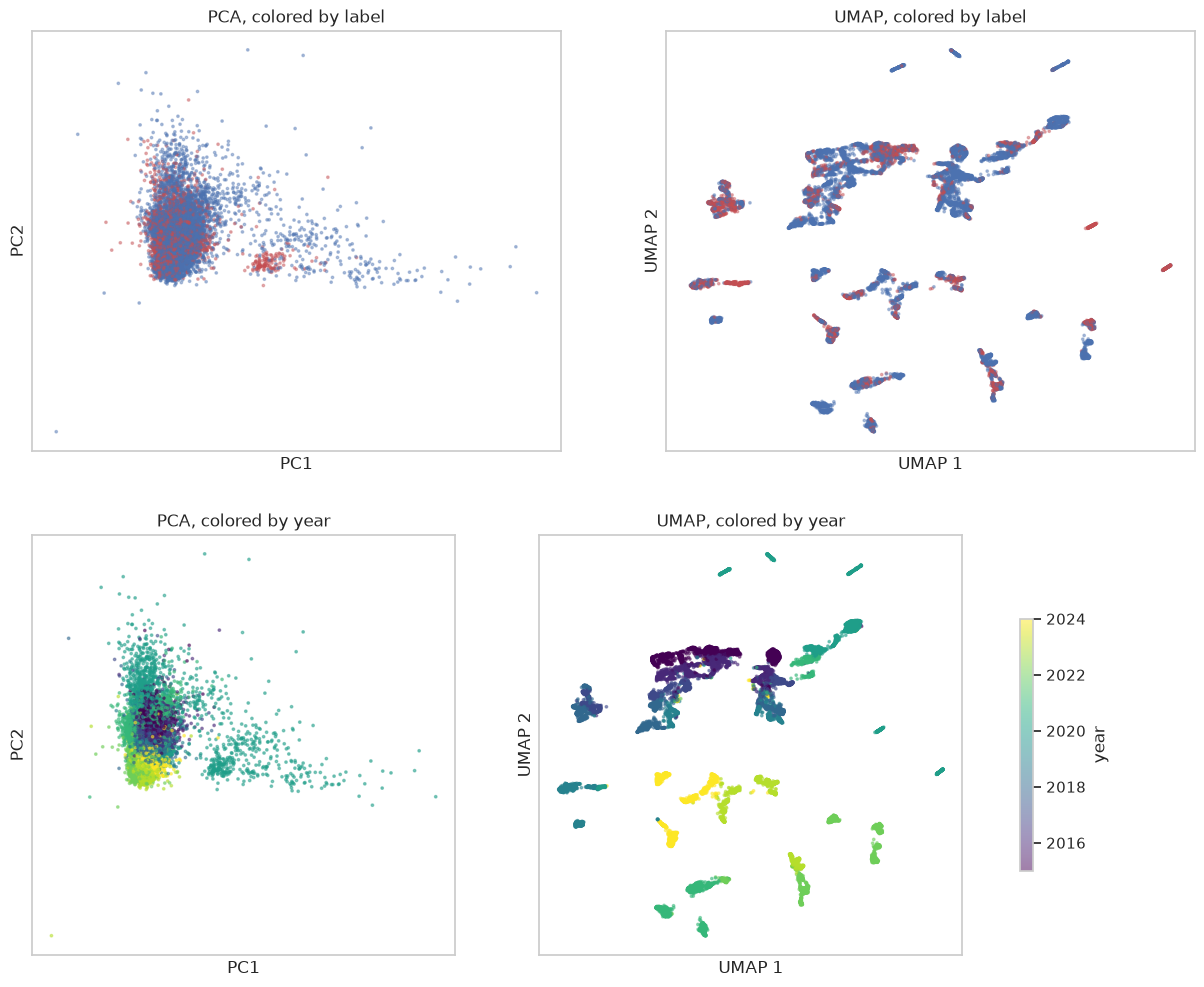

In [32]:
import umap
t0 = time.time()
U2 = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=RNG).fit_transform(Z_viz)
print(f"UMAP 2D on {len(Z_viz):,} rows in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
lab_colors = np.where(y_viz == 1, "#C44E52", "#4C72B0")
axes[0, 0].scatter(P2[:, 0], P2[:, 1], c=lab_colors, s=3, alpha=0.4); axes[0, 0].set_title("PCA, colored by label")
axes[0, 1].scatter(U2[:, 0], U2[:, 1], c=lab_colors, s=3, alpha=0.4); axes[0, 1].set_title("UMAP, colored by label")
axes[1, 0].scatter(P2[:, 0], P2[:, 1], c=yr_viz, s=3, alpha=0.5, cmap="viridis"); axes[1, 0].set_title("PCA, colored by year")
sc = axes[1, 1].scatter(U2[:, 0], U2[:, 1], c=yr_viz, s=3, alpha=0.5, cmap="viridis"); axes[1, 1].set_title("UMAP, colored by year")
plt.colorbar(sc, ax=axes[1, :], label="year", shrink=0.6)
for ax in axes.flat: ax.set_xticks([]); ax.set_yticks([])
for ax in axes[:, 0]: ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
for ax in axes[:, 1]: ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
plt.show()

**Comparing the views.** UMAP typically breaks the data into islands that line up with **time** (macro regimes and calendar months,
since every county in a month shares the FRED values and the seasonal features), rather than with the label. Red-heavy regions inside
the islands are the interesting part: they're local neighborhoods where rises concentrate. That's nonlinear structure a single linear
boundary can't capture.

Finally, as a quantitative check, a 10-dimensional UMAP embedding replaces the features, followed by the same logistic regression.

In [33]:
fit_idx = np.random.default_rng(RNG + 1).choice(len(train), 20_000, replace=False)
t0 = time.time()
reducer = umap.UMAP(n_components=10, n_neighbors=30, min_dist=0.0, random_state=RNG).fit(Z_train[fit_idx])
U_tr = reducer.embedding_
U_te = reducer.transform(prep.transform(X_test))
print(f"UMAP-10 fit on 20k rows + transform of {len(X_test):,} test rows in {time.time() - t0:.0f}s")

u_lr = Pipeline([("scale", StandardScaler()), ("lr", LogisticRegression(C=1.0, max_iter=2000))]).fit(U_tr, y_train[fit_idx])
probs["UMAP-10 + LR"] = u_lr.predict_proba(U_te)[:, 1]
same_n = make_lr(C=best_C, l1_ratio=best_l1).fit(X_train.iloc[fit_idx], y_train[fit_idx])
probs["LR raw features (same 20k rows)"] = same_n.predict_proba(X_test)[:, 1]

final = pd.concat([results, pd.DataFrame(pca_rows).set_index("model"),
                   pd.DataFrame([evaluate("UMAP-10 + LR (20k train rows)", y_test, probs["UMAP-10 + LR"], thr=THR),
                                 evaluate("LR raw features (same 20k rows)", y_test, probs["LR raw features (same 20k rows)"], thr=THR)]).set_index("model")])
final.style.format("{:.4f}", na_rep="–").highlight_min(subset=["log_loss", "brier"], color="#d4edda").highlight_max(subset=["roc_auc", "pr_auc", "f1"], color="#d4edda")

/workspaces/county_unemployment_project/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP-10 fit on 20k rows + transform of 37,716 test rows in 50s


,threshold,log_loss,brier,roc_auc,pr_auc,accuracy,precision,recall,f1
model,,,,,,,,,
Dummy (prior),0.5000,0.6013,0.2055,0.5000,0.2884,0.7116,0.0000,0.0000,0.0000
Seasonal-naive rule,–,–,–,–,–,0.7940,0.6247,0.7156,0.6671
LR unpenalized,0.2969,0.4975,0.1629,0.7991,0.6432,0.7672,0.5981,0.5875,0.5927
LR L1 (C=0.1),0.2969,0.4975,0.1630,0.7990,0.6436,0.7666,0.5972,0.5862,0.5916
LR L2 (C=0.1),0.2969,0.4978,0.1631,0.7985,0.6430,0.7657,0.5953,0.5864,0.5908
LR elastic net ρ=0.25 (C=0.1),0.2969,0.4977,0.1631,0.7986,0.6432,0.7660,0.5958,0.5862,0.5909
LR elastic net ρ=0.5 (C=0.1),0.2969,0.4976,0.1630,0.7987,0.6433,0.7663,0.5964,0.5860,0.5912
LR elastic net ρ=0.75 (C=0.1),0.2969,0.4976,0.1630,0.7989,0.6435,0.7665,0.5970,0.5861,0.5915
PCA k=11 (90% var) + LR,0.2969,0.5846,0.2005,0.6492,0.4020,0.5779,0.3774,0.7139,0.4938


**Fair comparison.** UMAP was fit on 20k rows, so it's compared with LR on the raw features trained on *the same* 20k rows (the last
row), not with the model trained on 380k. Note that UMAP features would also be awkward in real-time use: `transform` is slow,
stochastic, and the embedding must be refit and stored alongside the model.

Note also: the threshold used here came from CV on the raw-feature LR. Models whose probabilities are on a different scale (UMAP-LR,
PCA-LR) may have a different best threshold, so compare them mainly on the threshold-free metrics (log loss, ROC AUC, PR AUC).

## 8. Summary

See the printed summary below (generated from this run's results), then the discussion.

In [34]:
lr_rows = results.loc[[i for i in results.index if i.startswith("LR ")]]
print(f"Test year: {test.month.min():%Y-%m} to {test.month.max():%Y-%m}, {len(test):,} rows, positive rate {y_test.mean():.3f}")
print(f"Seasonal-naive F1: {results.loc['Seasonal-naive rule', 'f1']:.3f}")
print(f"Best penalized LR on test: {best_name}")
print(final.loc[[best_name, "LR unpenalized", "Dummy (prior)"], ["log_loss", "roc_auc", "pr_auc", "f1"]].round(4).to_string())
print(f"Spread in test ROC AUC across penalties: {lr_rows.roc_auc.max() - lr_rows.roc_auc.min():.4f}")

Test year: 2025-04 to 2026-05, 37,716 rows, positive rate 0.288
Seasonal-naive F1: 0.667
Best penalized LR on test: LR L1 (C=0.1)
                log_loss  roc_auc  pr_auc     f1
model                                           
LR L1 (C=0.1)     0.4975   0.7990  0.6436 0.5916
LR unpenalized    0.4975   0.7991  0.6432 0.5927
Dummy (prior)     0.6013   0.5000  0.2884 0.0000
Spread in test ROC AUC across penalties: 0.0006


### Discussion (numbers from the run on 2026-10-24; they will move slightly when the data updates)

**Test period.** The 12 newest labeled months span 2025-04 to 2026-05. Two months are missing: **October 2025 has no county
rate in LAUS** (it looks like the BLS gap from the 2025 federal shutdown), so October 2025 and July 2025 (whose t+3 is October) have no label.
Test positive rate: 0.288.

**1. Regularization barely matters.** Each penalty's best point is at C = 0.1, and they are all within noise:
CV log loss 0.4903–0.4910 (fold sd ≈ 0.06), CV ROC AUC ≈ 0.842. On the test year, ROC AUC differs by only 0.0006 across L1/L2/elastic net
and matches unpenalized LR (0.799). With 26 features and 377k rows there is little overfitting for a penalty to fix.
L1's value is **interpretive** (the path in §4.1), not predictive.

**2. The model does not beat the seasonal-naive rule on hard decisions.** This is the most important result here.
"Flag if this county rose ≥ 0.5 pp over the same window last year" gets **F1 0.667 / accuracy 0.794** on the test year, versus
**F1 0.59 / accuracy 0.767** for the best LR. The LR features describe season only as `f_month_sin/cos`, which is the *same* for every
county. They can't express that *this* county's seasonal pattern differs from another's, but last year's same-window change does.
The obvious next step is to add `rate(t−9) − rate(t−12)` (and maybe `rate(t−21) − rate(t−24)`) as features in the mart.

**3. CV is optimistic versus the future.** CV ROC AUC 0.842 → test 0.799. Grouping by quarter removes near-duplicate leakage,
but CV folds still mix years, so the model is graded on regimes it has seen. The out-of-time test number is the one to trust.

**4. COVID hurts training.** Refitting without 2020–21 improves the test year: ROC AUC 0.799 → **0.827**, log loss 0.498 → **0.464**,
F1 0.59 → 0.64 (§5.5). The COVID months teach relationships (huge national shocks) that don't hold in normal years. Consider
dropping or down-weighting them.

**5. Threshold.** The F1-optimal threshold from out-of-fold predictions is ≈ 0.30, not 0.5. At 0.5 the model is far too conservative
for a 27–29% positive problem.

**6. PCA: useful lens, harmful preprocessing.** 11 components hold 90% of the variance, but LR on them drops test ROC AUC from 0.80 to
**0.65**. CV picked *all 26* components, which is just a rotation of the original model (same 0.798). The predictive signal sits partly
in **low-variance directions** that variance-based truncation throws away.

**7. UMAP: no help, and unstable out of time.** In 2D, UMAP mostly organizes the data by time/regime. LR on a 10-D UMAP embedding scored
test ROC AUC **0.41**, which is *below chance*, while LR on the raw features from the same 20k rows got 0.78. The embedding learned on
past years doesn't transfer to new months (`transform` places new regimes in the wrong neighborhoods). It isn't a viable feature
for real-time use.

**Next steps (your call).** (a) Add county-specific seasonal features, (b) drop/down-weight 2020–21, (c) try gradient-boosted trees,
which can learn county × season interactions directly, and (d) keep the seasonal-naive rule as the bar every model must beat.
Notebook 02 tests support vector machines against this LR and also tries leads (a) and (b).

**Caveats.** One test year is one regime. Training labels are revised LAUS history, while real-time use would see preliminary data.
County rates aren't seasonally adjusted. No model is saved; notebook 03 (`03_final_model.ipynb`) makes the final choice.